# Breaking the Blend - automated decomposition of IFS data (example: NGC 5728)

This notebook is an **automated implementation of the Breaking the Blend method** (Veenema et al. 2026):
separating, spaxel by spaxel, the emission of two physically distinct components - here a circumnuclear
star-forming disc/ring and an AGN-driven biconical outflow - using many emission lines at once.

The example loads JWST NIRSpec + MIRI/MRS data of **NGC 5728**, but every choice (target, cubes, lines,
fit settings, model parameters, which component each line traces) is set in a few clearly marked cells
and can be changed for any other galaxy or set of lines.

| Section | What happens | Module |
|---|---|---|
| 0 | Settings for this analysis (name, data folder, redshift, run switches) | `project` |
| 1 | Find & load cubes, check the AGN position | `cubes` |
| 2 | Choose the emission lines and their fit settings | `lines` |
| 3 | **Step 1** - flux, single-/double-Gaussian and moment maps, dispersion of each component | `linefit`, `dispersion` |
| 4 | **Step 2** - disc / bicone / combined velocity models (fitted, fixed, or imported from other codes), geometry schematic | `models`, `kinfit`, `external`, `geometry` |
| 5 | **Step 3** - constrained decomposition -> disc fraction $f_{\rm disc}$ per line | `decompose` |
| 6 | **Step 4** - weighted stack of all lines -> AGN outflow fraction map | `stacking` |
| 7 | **Step 5** - AGN- and star-formation-dominated spectra | `extraction` |

Every slow step is **saved** in `results/<GALAXY>/` and re-loaded next time; if its settings change it is recomputed
automatically (`RERUN_*` forces a re-run). Figures go to `results/<GALAXY>/figures/`, settings to `config.json`.

**Data.** Download the public MAST cubes into `data/NGC5728/` first (see `data/NGC5728/README.md`). MAST cubes are
reduced with the current JWST pipeline, so results will be close to, but not identical with, the published ones.

**About the example settings.** An automated analysis cannot make every per-line choice that a careful by-hand
analysis does. To reproduce the published NGC 5728 maps closely, this example therefore adopts several settings
of the original analysis (per-line masks, AGN positions, fit windows and the per-line best-fit model parameters
and dispersions). Each is marked *"original NGC 5728 analysis"* and can be switched to the automated / newly
fitted values. Results obtained with different choices will differ in detail - see the notes at the end.

## 0. Settings

In [1]:
# =====================================================================
# 0. ANALYSIS SETTINGS - edit this cell for a new galaxy / analysis
# =====================================================================
GALAXY       = "NGC5728"            # analysis name -> results are saved in RESULTS_DIR/GALAXY/
DATA_DIR     = "/Users/veenema/Documents/NGC5728/MRS/"    # folder with the *_s3d.fits(.gz) cubes (searched recursively) - see data/NGC5728/README.md
RESULTS_DIR  = "results"            # parent folder for all analyses
Z            = 0.00935              # redshift
DISTANCE_MPC = None                 # e.g. 39 to fix the physical scale; None = from the redshift

# Re-run switches: False -> load the saved result if it exists (and its settings are unchanged)
RERUN_LINE_FITS     = False
RERUN_KINEMATICS    = False
RERUN_DECOMPOSITION = False

# Kinematic fitting (Step 2). The paper used nsteps=150000, burnin=50000 (slow).
# method="least_squares" is much faster for exploring. sigma_v sets the velocity uncertainty per spaxel
# in the likelihood: "residual" (scatter about the best fit; realistic errors) or "std" (scatter of the map).
MCMC = dict(method="emcee", nwalkers=32, nsteps=20000, burnin=5000, sigma_v="residual")

# Figure output: "png", "pdf", "both" or "none"  (saved in RESULTS_DIR/GALAXY/figures/)
SAVE_FIGURES = "both"
FIGURE_DPI   = 200

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
try:
    import breaking_the_blend as btb
except ModuleNotFoundError:   # not installed (pip install -e .): use the copy in this repository
    import sys, os
    sys.path.insert(0, os.path.abspath(".."))
    import breaking_the_blend as btb
from breaking_the_blend import plotting as bplt     # also sets the publication plotting style

proj = btb.Project(GALAXY, data_dir=DATA_DIR, z=Z, distance_mpc=DISTANCE_MPC, results_dir=RESULTS_DIR,
                   save_figures=SAVE_FIGURES, figure_dpi=FIGURE_DPI)

Project 'NGC5728': results in /Users/veenema/Documents/BTB_github/breaking-the-blend/notebooks/results/NGC5728


## 1. Data: find the cubes and locate the AGN

**Getting the data.** The cubes are public on MAST (JWST programmes **1670**, MIRI/MRS, and **5017**, NIRSpec IFU).
Download them into `data/NGC5728/` with the script (from the repository root):
`python scripts/download_mast_cubes.py --target "NGC 5728" --programs 1670 5017 --out data/NGC5728`,
or via the MAST portal - full instructions in `data/NGC5728/README.md`.

`find_cubes` searches `DATA_DIR` (and all sub-folders, e.g. a raw MAST download) for `*s3d.fits*` files and
names each by its band (`ch3-short`, `g395h-f290lp`, ...). Use `exclude=[...]` to skip files, or
`proj.set_cube_files({...})` to give them by hand. Cubes are converted to **Jy/pixel** and de-redshifted.

The AGN position of each cube defaults to the (centroided) continuum peak. All maps are then expressed as
**offsets from the AGN in parsec**, so bands with different pixel sizes line up. `AGN_OVERRIDES` sets positions
by hand (here: the positions adopted in the original NGC 5728 analysis).

The pixel size is read from each cube header (`PIXEL_SCALE_OVERRIDES` can replace it). The overview figure marks the
continuum peak of each cube; the printed table lists the adopted AGN positions.

In [4]:
files = proj.find_cubes(exclude=["*bkg*"])

Found 13 cubes in /Users/veenema/Documents/NGC5728/MRS:
        ch1-long: Level3_ch1-long_s3d.fits.gz
      ch1-medium: Level3_ch1-medium_s3d.fits.gz
       ch1-short: Level3_ch1-short_s3d.fits.gz
        ch2-long: Level3_ch2-long_s3d.fits.gz
      ch2-medium: Level3_ch2-medium_s3d.fits.gz
       ch2-short: Level3_ch2-short_s3d.fits.gz
        ch3-long: Level3_ch3-long_s3d.fits.gz
      ch3-medium: Level3_ch3-medium_s3d.fits.gz
       ch3-short: Level3_ch3-short_s3d.fits.gz
        ch4-long: Level3_ch4-long_s3d.fits.gz
      ch4-medium: Level3_ch4-medium_s3d.fits.gz
       ch4-short: Level3_ch4-short_s3d.fits.gz
    g395h-f290lp: ngc5728_level3_dectboth_sky_g395h-f290lp_s3d.fits


Cube('ch1-long', 6.470-7.579 um, shape=(1400, 77, 81), 0.130"/pix = 25.8 pc/pix, agn_xy=None)
Cube('ch1-medium', 5.608-6.569 um, shape=(1213, 77, 81), 0.130"/pix = 25.8 pc/pix, agn_xy=None)
Cube('ch1-short', 4.855-5.686 um, shape=(1050, 77, 81), 0.130"/pix = 25.8 pc/pix, agn_xy=None)
Cube('ch2-long', 9.918-11.591 um, shape=(1300, 67, 71), 0.170"/pix = 33.8 pc/pix, agn_xy=None)
Cube('ch2-medium', 8.590-10.037 um, shape=(1124, 67, 69), 0.170"/pix = 33.8 pc/pix, agn_xy=None)
Cube('ch2-short', 7.441-8.689 um, shape=(970, 67, 71), 0.170"/pix = 33.8 pc/pix, agn_xy=None)
Cube('ch3-long', 15.268-17.812 um, shape=(1028, 67, 71), 0.200"/pix = 39.7 pc/pix, agn_xy=None)
Cube('ch3-medium', 13.218-15.425 um, shape=(892, 67, 71), 0.200"/pix = 39.7 pc/pix, agn_xy=None)
Cube('ch3-short', 11.444-13.346 um, shape=(769, 67, 71), 0.200"/pix = 39.7 pc/pix, agn_xy=None)
Cube('ch4-long', 24.177-28.433 um, shape=(717, 47, 47), 0.350"/pix = 69.5 pc/pix, agn_xy=None)
Cube('ch4-medium', 20.501-24.252 um, shape=(6

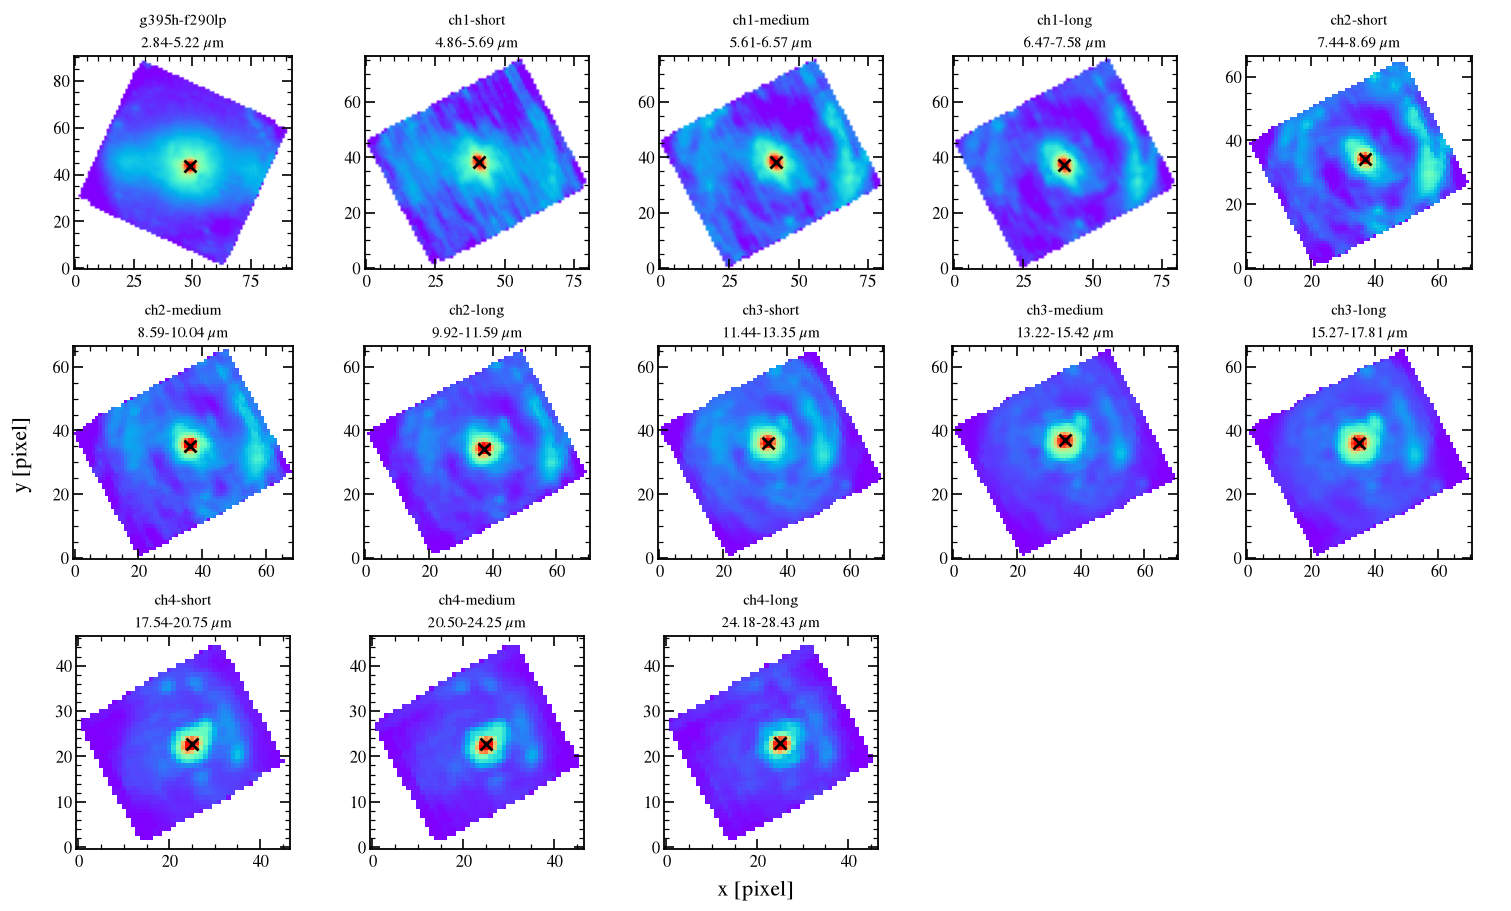

In [5]:
# AGN pixel positions (x, y) adopted in the original NGC 5728 analysis. These only apply to the cubes used in that
# analysis (GATOS reduction): for cubes downloaded from MAST keep USE_ORIGINAL_AGN_XY = False, which uses the
# continuum peak of every cube (pixel grids differ between reductions).
USE_ORIGINAL_AGN_XY = False
ORIGINAL_AGN_XY = {"ch1-short": (39.8, 39.5), "ch1-long": (39.8, 38.5), "ch2-short": (36.8, 32.0),
                   "ch2-medium": (36.7, 35.5), "ch2-long": (37.7, 34.5), "ch3-short": (34.0, 37.0),
                   "ch3-medium": (35.0, 37.5), "ch3-long": (34.7, 36.5), "ch4-short": (24.5, 22.5),
                   "ch4-long": (24.8, 22.1), "g395h-f290lp": (49.0, 43.5)}
AGN_OVERRIDES = ORIGINAL_AGN_XY if USE_ORIGINAL_AGN_XY else {}

PIXEL_SCALE_OVERRIDES = {}          # {"cube": arcsec} only if a header pixel size is wrong

LOAD_ERR = True                     # also read the ERR extensions (spectrum errors in Step 5; doubles cube memory)

cubes = proj.load_cubes(agn_overrides=AGN_OVERRIDES, pixel_scale_overrides=PIXEL_SCALE_OVERRIDES, load_err=LOAD_ERR)
fig = bplt.plot_cubes_overview(cubes)
proj.savefig(fig, "cubes_overview")

## 2. Emission lines

Each line is a `btb.LineSpec` (see `btb.LINE_CATALOGUE`). Pick lines by name, then change any setting in
`LINE_SETTINGS`:

* `cube` - cube to measure the line in (left out -> chosen automatically);
* `line_region` - rest-frame range ($\mu$m) holding the line: excluded from the continuum fit and integrated;
* `fit_window` - range cut out of the cube (default `line_region` $\pm$ 0.02 $\mu$m);
* `p0_amp_frac`, `p0_dv_kms`, `p0_sigma_kms` - initial (narrow, broad) amplitude fraction, velocity offset and
  dispersion of the double-Gaussian fit;
* `mask_percentile` - spaxels fainter than this flux percentile are masked.

The values below are those of the original NGC 5728 analysis (initial guesses converted from microns to km/s).
A line not in the catalogue can be added with `btb.LineSpec("name", "label", wavelength, IP)`.

In [7]:
LINES = ["FeII", "ArII", "NeII", "SIII", "ArIII", "SIV", "NeIII", "OIV", "ArVI", "MgIV", "NeV", "NeVI"]

LINE_SETTINGS = {   # original NGC 5728 analysis
    "FeII":  dict(cube="ch1-short",  line_region=(5.320, 5.355),  mask_percentile=55,
                  p0_amp_frac=(0.67, 0.33), p0_dv_kms=(-2.8, 1.1),  p0_sigma_kms=(112, 225)),
    "ArII":  dict(cube="ch1-long",   line_region=(6.975, 7.000),  mask_percentile=50,
                  p0_amp_frac=(0.77, 0.50), p0_dv_kms=(-21.5, 4.3), p0_sigma_kms=(86, 215)),
    "NeII":  dict(cube="ch3-short",  line_region=(12.800, 12.830), mask_percentile=70,
                  p0_amp_frac=(0.50, 0.33), p0_dv_kms=(-23.4, 2.3), p0_sigma_kms=(105, 164)),
    "SIII":  dict(cube="ch4-short",  line_region=(18.650, 18.780), mask_percentile=55,
                  p0_amp_frac=(0.71, 0.40), p0_dv_kms=(-2.4, 3.2),  p0_sigma_kms=(112, 152)),
    "ArIII": dict(cube="ch2-medium", line_region=(8.980, 9.015),  mask_percentile=55,
                  p0_amp_frac=(0.71, 0.43), p0_dv_kms=(-1.7, 1.7),  p0_sigma_kms=(100, 200)),
    "SIV":   dict(cube="ch2-long",   line_region=(10.485, 10.535), mask_percentile=55,
                  p0_amp_frac=(0.67, 0.33), p0_dv_kms=(0.0, 28.5),  p0_sigma_kms=(86, 257)),
    "NeIII": dict(cube="ch3-long",   line_region=(15.520, 15.600), mask_percentile=60,
                  p0_amp_frac=(0.77, 0.33), p0_dv_kms=(-3.9, 3.9),  p0_sigma_kms=(106, 173)),
    "OIV":   dict(cube="ch4-long",   line_region=(25.830, 25.970), mask_percentile=55,
                  p0_amp_frac=(0.67, 0.33), p0_dv_kms=(0.0, 1.2),   p0_sigma_kms=(81, 127)),
    "ArVI":  dict(cube="g395h-f290lp", line_region=(4.524, 4.537), mask_percentile=55,
                  p0_amp_frac=(0.33, 0.50), p0_dv_kms=(-3.3, 3.3),  p0_sigma_kms=(66, 165)),
    "MgIV":  dict(cube="g395h-f290lp", line_region=(4.481, 4.492), mask_percentile=55,
                  p0_amp_frac=(0.33, 0.67), p0_dv_kms=(-0.7, 0.1),  p0_sigma_kms=(134, 267)),
    "NeV":   dict(cube="ch3-medium", line_region=(14.295, 14.345), fit_window=(14.265, 14.350),  # avoid [Cl II]
                  mask_percentile=50),
    "NeVI":  dict(cube="ch2-short",  line_region=(7.645, 7.670),  mask_percentile=50,
                  p0_amp_frac=(0.33, 0.67), p0_dv_kms=(-0.4, 0.0),  p0_sigma_kms=(78, 176)),
}

lines = btb.get_lines(LINES)                                         # ordered by IP
lines = {n: l.update(**LINE_SETTINGS.get(n, {})) for n, l in lines.items()}
lines = btb.assign_cubes(lines, cubes)                               # checks / fills the cube of each line
proj.save_config(lines=lines)

[Fe II]     5.3390 um   IP =    7.9 eV   cube = ch1-short
[Ar II]     6.9845 um   IP =   15.8 eV   cube = ch1-long
[Ne II]    12.8140 um   IP =   21.6 eV   cube = ch3-short
[S III]    18.7120 um   IP =   23.3 eV   cube = ch4-short
[Ar III]    8.9905 um   IP =   27.6 eV   cube = ch2-medium
[S IV]     10.5100 um   IP =   34.9 eV   cube = ch2-long
[Ne III]   15.5580 um   IP =   41.0 eV   cube = ch3-long
[O IV]     25.8900 um   IP =   54.9 eV   cube = ch4-long
[Ar VI]     4.5300 um   IP =   74.8 eV   cube = g395h-f290lp
[Mg IV]     4.4870 um   IP =   80.1 eV   cube = g395h-f290lp
[Ne V]     14.3200 um   IP =   97.2 eV   cube = ch3-medium
[Ne VI]     7.6524 um   IP =  126.2 eV   cube = ch2-short


## 3. Step 1 - measure every line in every spaxel

For each line and spaxel `fit_lines` subtracts a polynomial continuum, integrates the line flux, masks spaxels
below `mask_percentile`, fits a **single** and a **double** Gaussian (the narrow component is always the one with
the smaller $\sigma$) and computes moment maps. Fit options:

* `fitter` - `"trf"` (bounded, default), `"lm"` (unbounded Levenberg-Marquardt) or `"capfit"` (unbounded CapFit,
  as in the original analysis; `pip install capfit`, falls back to `"lm"` if missing);
* `weighting` - `"none"`, `"err"` (cube ERR extension) or `"sqrt"` ($\sqrt{|f|}$ uncertainties, as in the original);
* `p0_center` - start the Gaussians at the moment-1 velocity (`"moment"`) or at systemic (`"systemic"`, original);
* `percentile_over` - flux percentile over the whole array (`"all"`, original) or inside the field of view (`"fov"`).

**These choices matter for the double-Gaussian dispersions** (next sub-section): the `"sqrt"` weighting gives the faint
line wings much more weight, which widens the broad component. No correction for the instrumental line-spread
function is applied (as in the paper), so that is not a source of difference. The options below reproduce the
original analysis; `fitter="trf", weighting="none", p0_center="moment", percentile_over="fov"` is a more
conservative automated choice.

In [10]:
FIT_OPTIONS = dict(fitter="capfit", weighting="sqrt", p0_center="systemic", percentile_over="all", dilate=2)

line_maps = proj.checkpoint("step1_line_maps", btb.fit_lines, cubes, lines, **FIT_OPTIONS,
                            rerun=RERUN_LINE_FITS, settings=dict(lines=lines, **FIT_OPTIONS))

  FeII:   0%|          | 0/997 [00:00<?, ?it/s]

/opt/anaconda3/envs/breaking-the-blend/lib/python3.11/site-packages/capfit/capfit.py:802: RuntimeWarning: invalid value encountered in scalar divide
  ratio = actred/prered


  -> LineMaps([Fe II], IP=7.9 eV, cube=ch1-short, 997 good spaxels)


  ArII:   0%|          | 0/2292 [00:00<?, ?it/s]

  -> LineMaps([Ar II], IP=15.8 eV, cube=ch1-long, 2292 good spaxels)


...

  -> LineMaps([Mg IV], IP=80.1 eV, cube=g395h-f290lp, 864 good spaxels)


   NeV:   0%|          | 0/1389 [00:00<?, ?it/s]

  -> LineMaps([Ne V], IP=97.2 eV, cube=ch3-medium, 1389 good spaxels)


  NeVI:   0%|          | 0/1220 [00:00<?, ?it/s]

  -> LineMaps([Ne VI], IP=126.2 eV, cube=ch2-short, 1220 good spaxels)
[NGC5728] 'step1_line_maps' done in 40 s
saved -> results/NGC5728/step1_line_maps.pkl


**Check the fits first.** If the double-Gaussian fits in a few spaxels look wrong, change `p0_*` / `line_region`
for that line in Section 2 (it is re-fitted automatically).

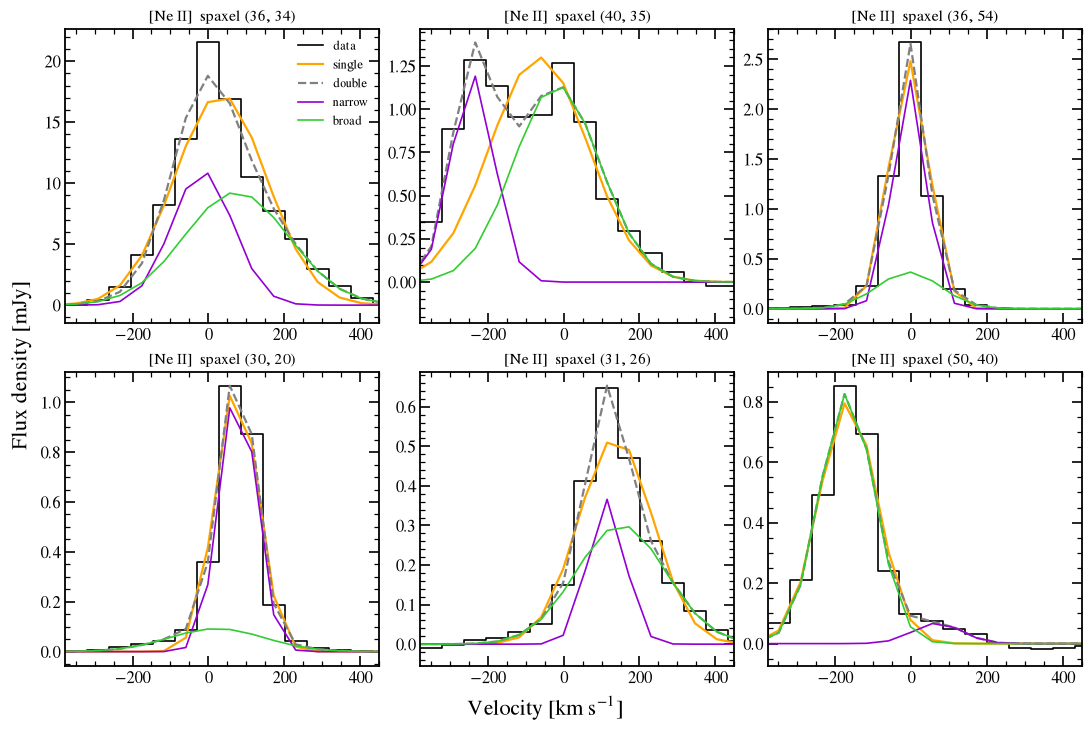

In [12]:
fig = bplt.plot_spaxel_fits(line_maps["NeII"], n=6);  proj.savefig(fig, "spaxel_fits_NeII")

### Flux and single-Gaussian maps (paper Figs. S1, S2)

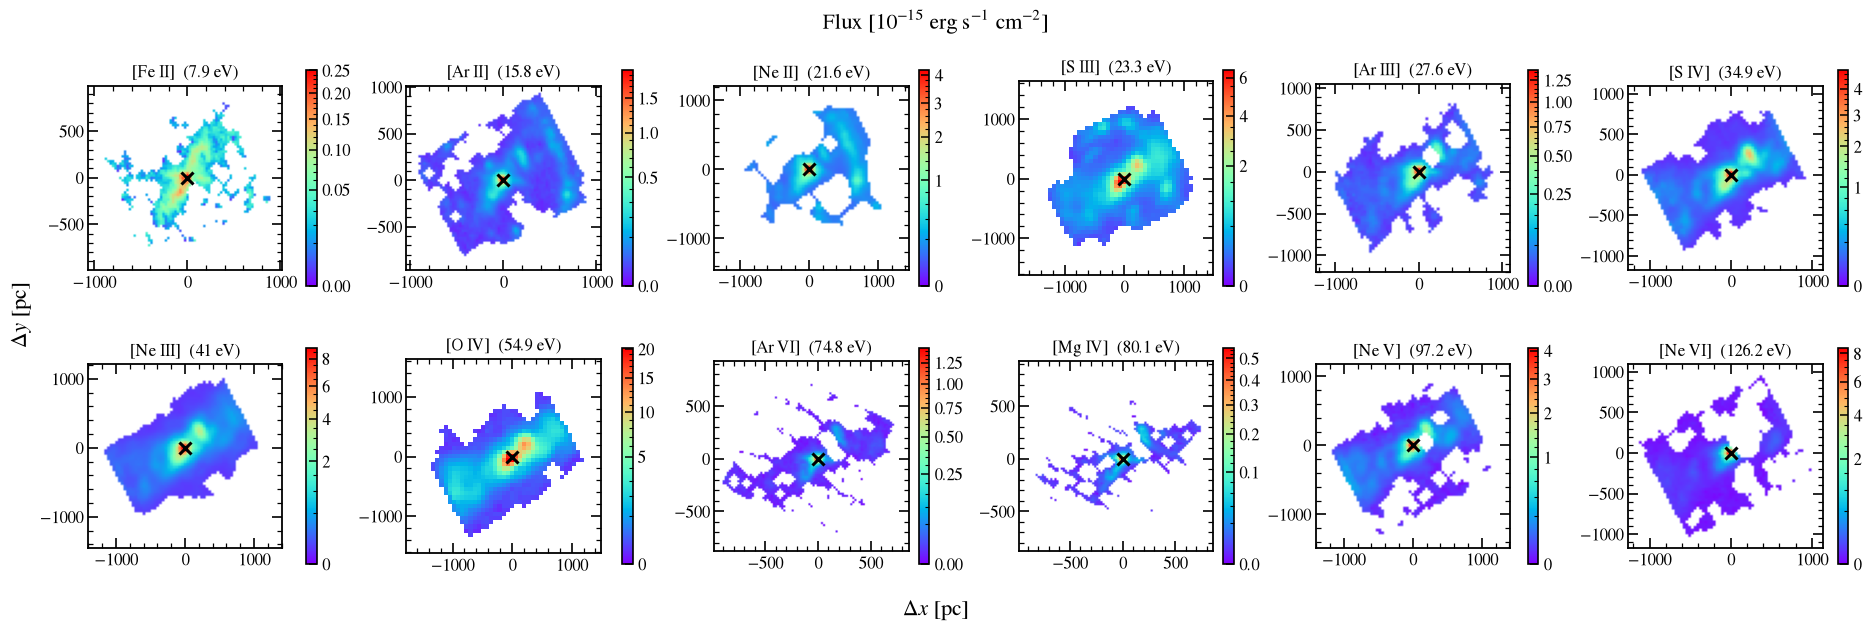

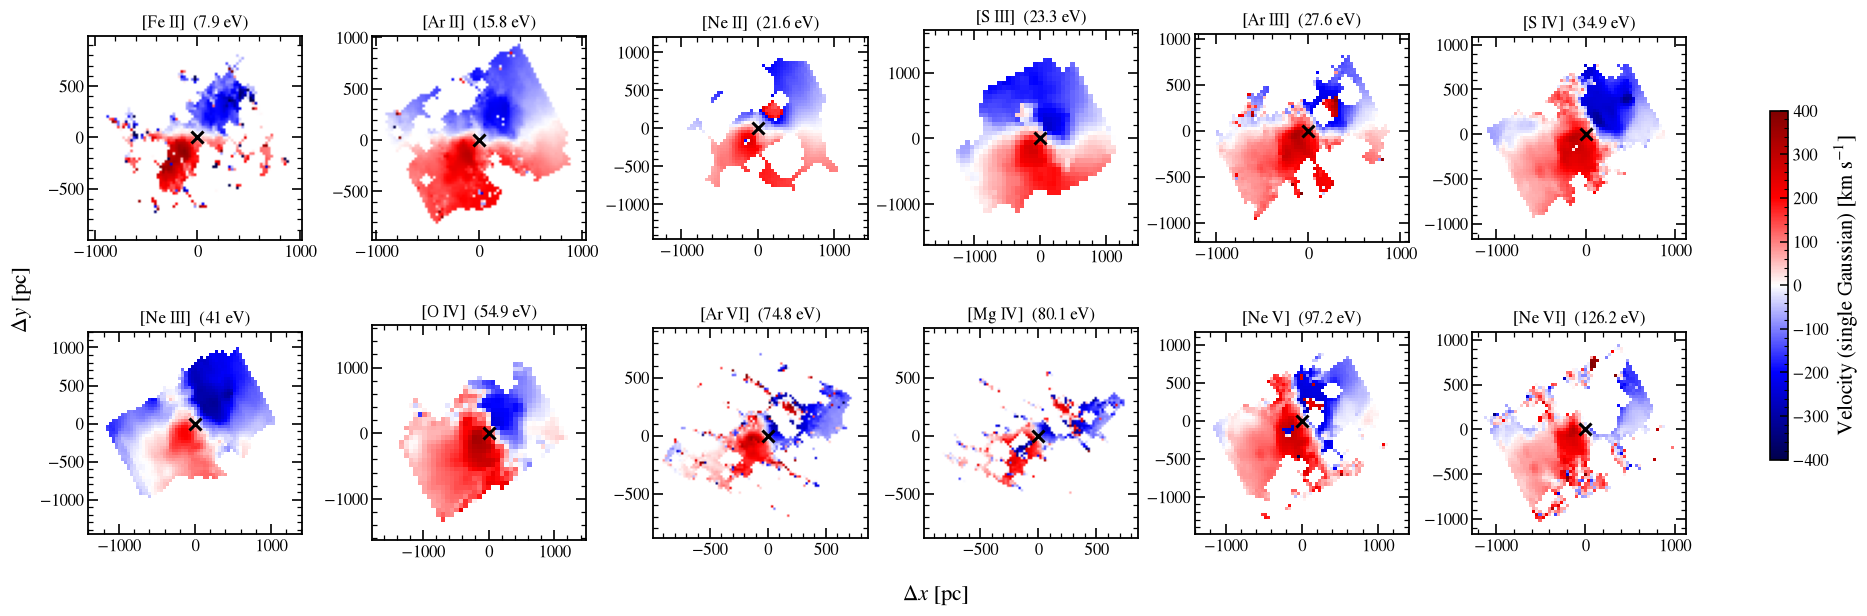

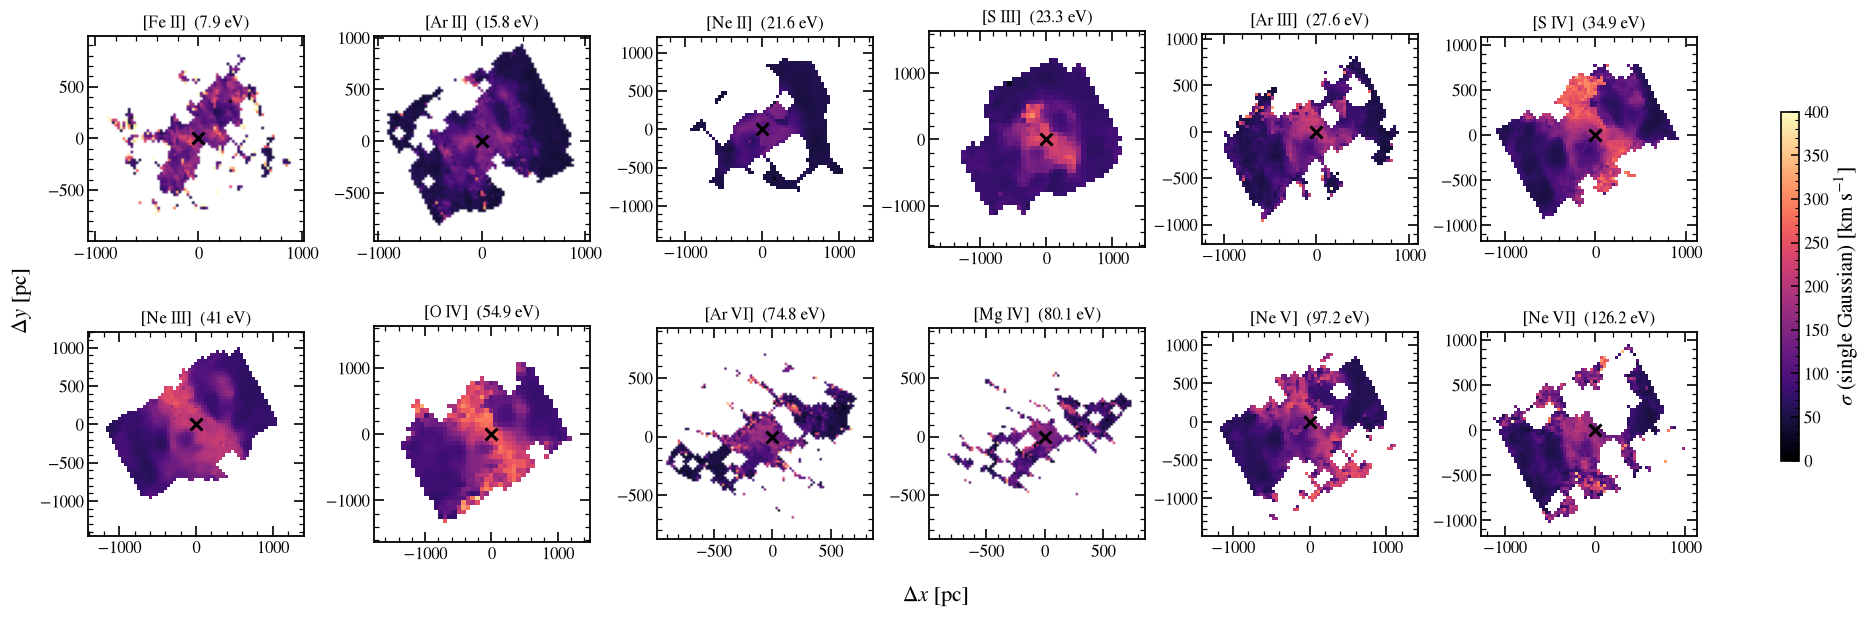

In [14]:
fig = bplt.plot_line_maps(line_maps, "flux");      proj.savefig(fig, "S1_flux_maps")
fig = bplt.plot_line_maps(line_maps, "velocity");  proj.savefig(fig, "S2_velocity_maps")
fig = bplt.plot_line_maps(line_maps, "sigma");     proj.savefig(fig, "single_gaussian_dispersion_maps")

These maps, ordered by IP, show the transition from disc-dominated (low IP) to outflow-dominated (high IP)
emission - they are where you decide **which lines trace which component** (used in Step 2).

### Double-Gaussian maps (narrow | broad)

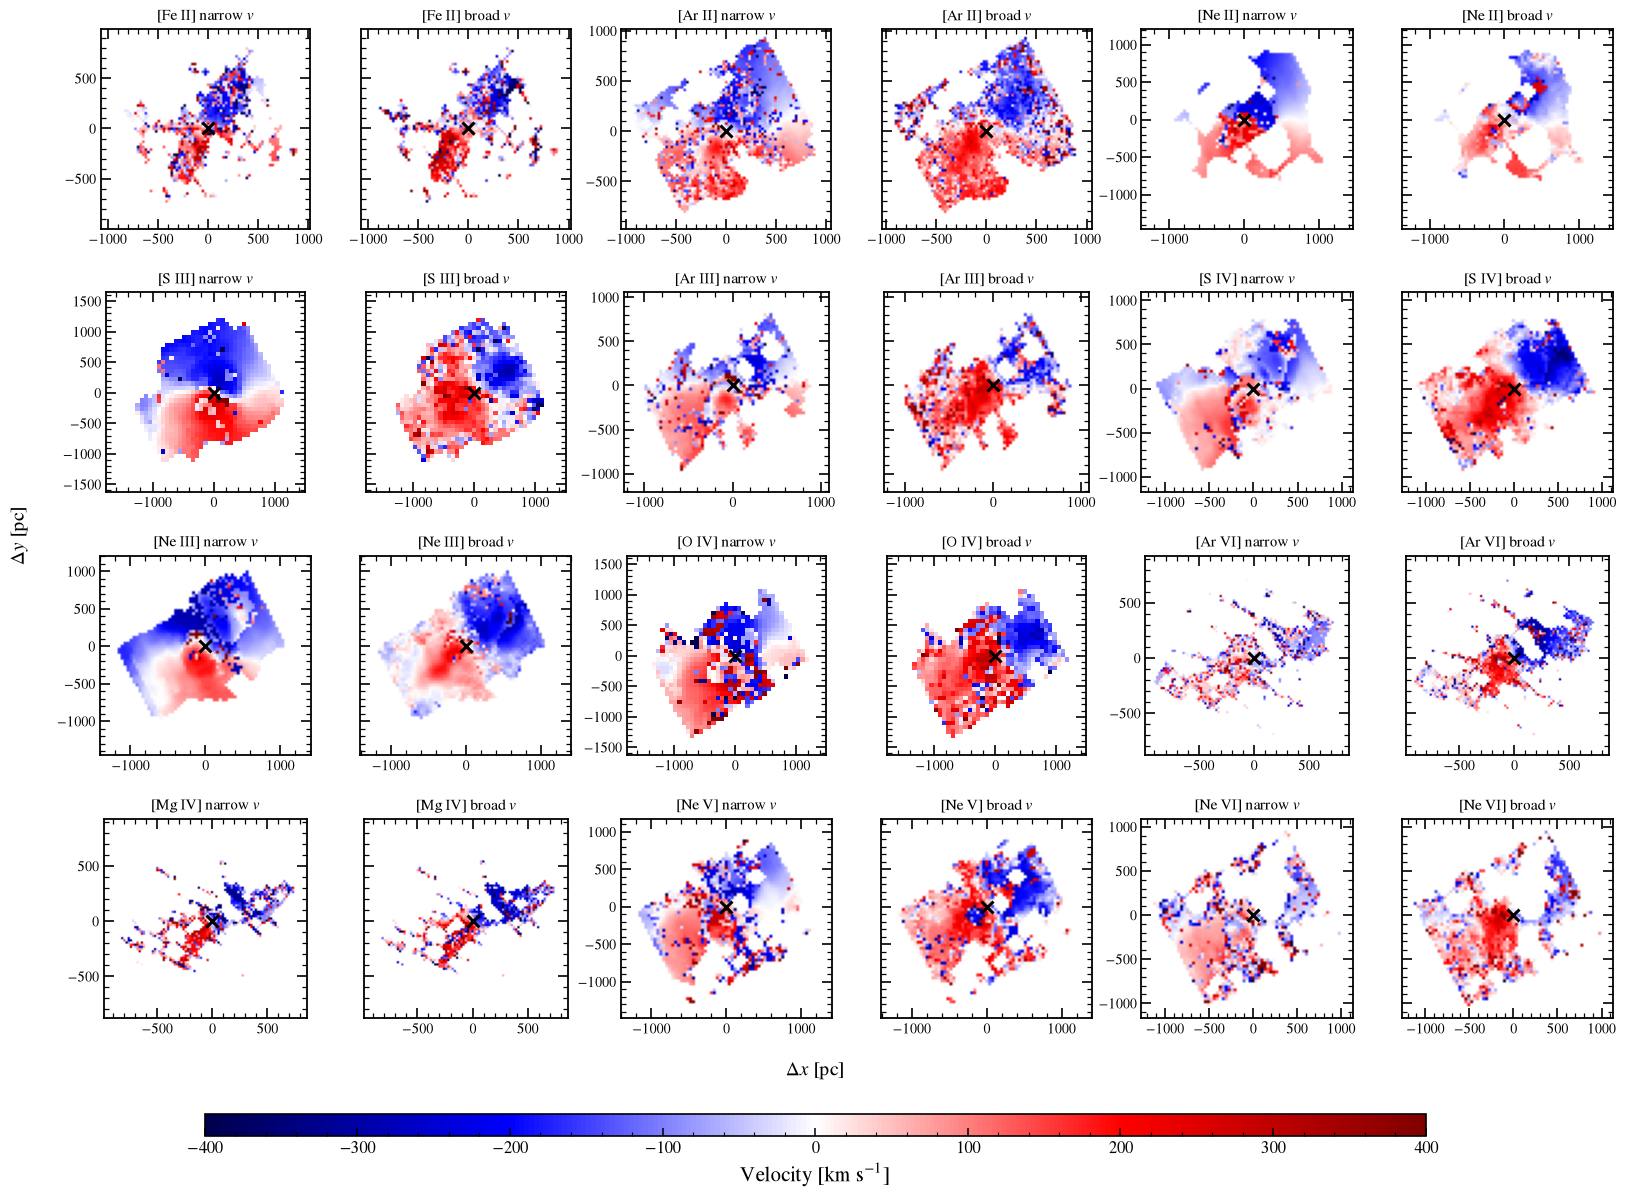

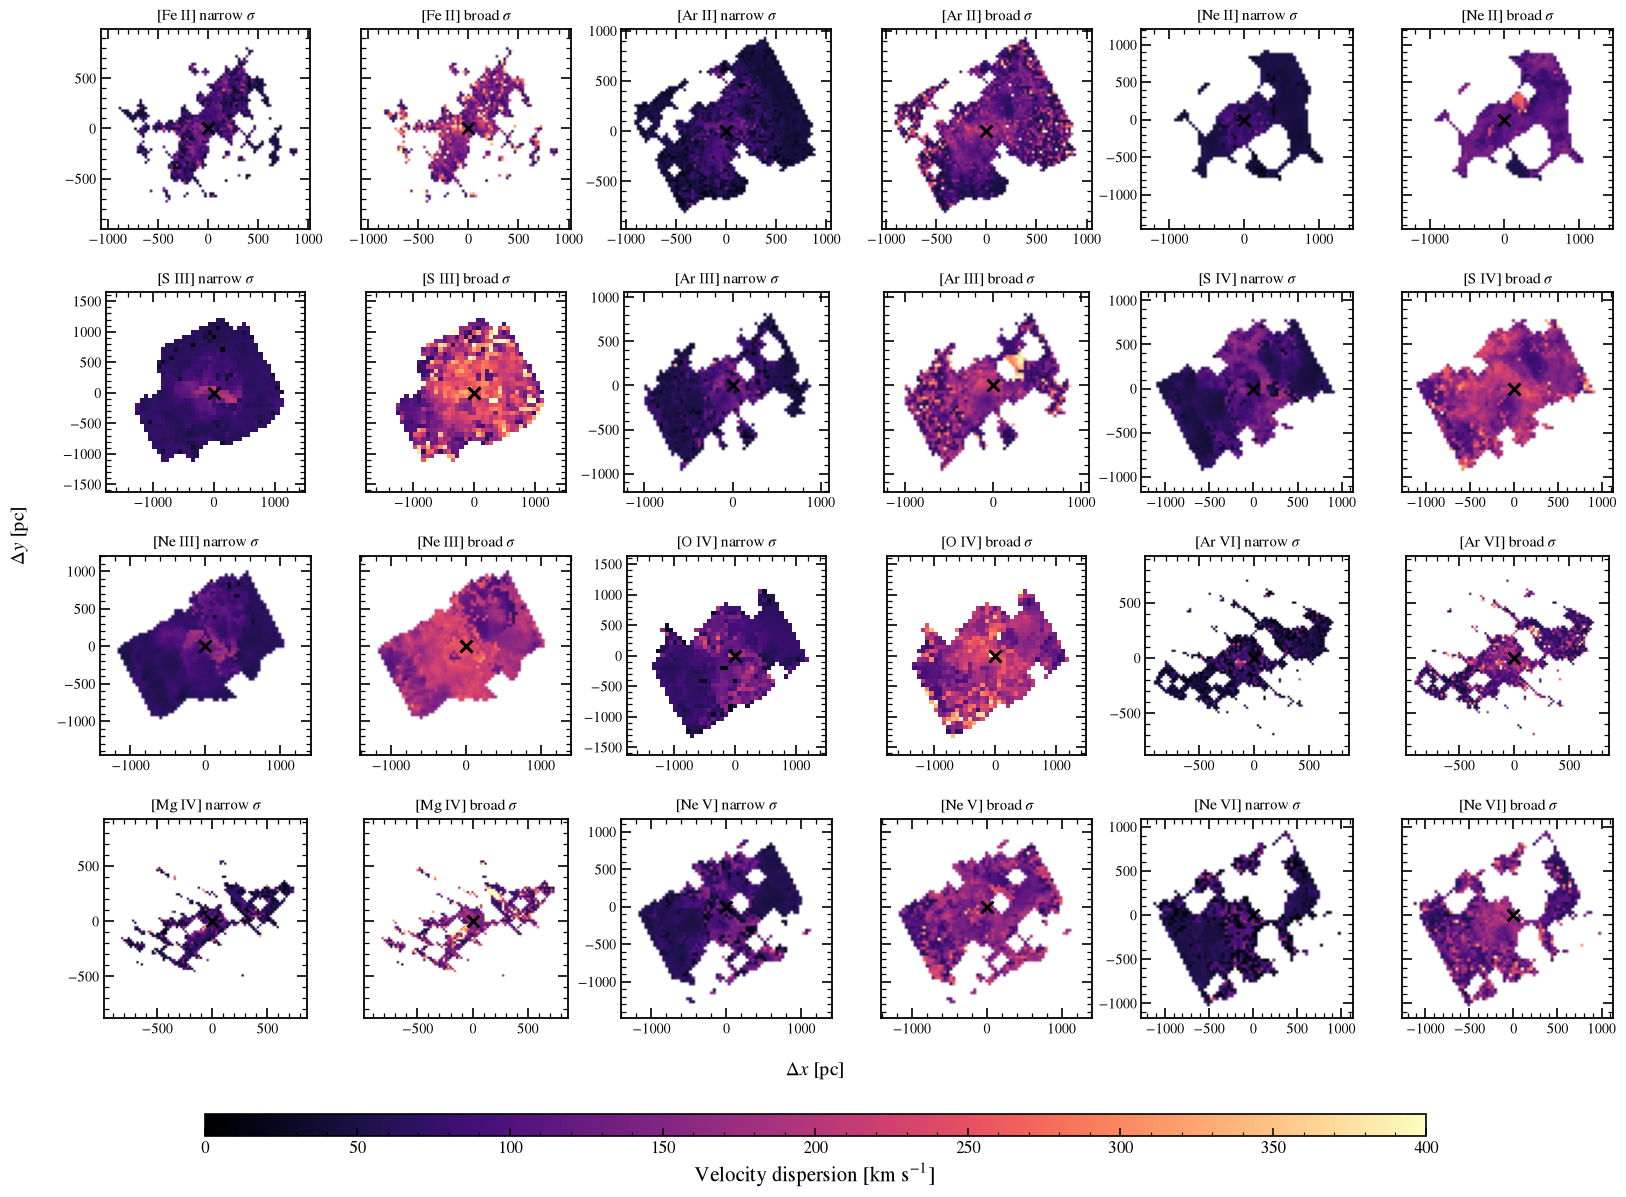

In [16]:
fig = bplt.plot_line_quantities(line_maps, ("v_n", "v_b"));          proj.savefig(fig, "double_gaussian_velocity_maps")
fig = bplt.plot_line_quantities(line_maps, ("sigma_n", "sigma_b"));  proj.savefig(fig, "double_gaussian_dispersion_maps")

### Moment maps (0: flux, 1: velocity, 2: dispersion)

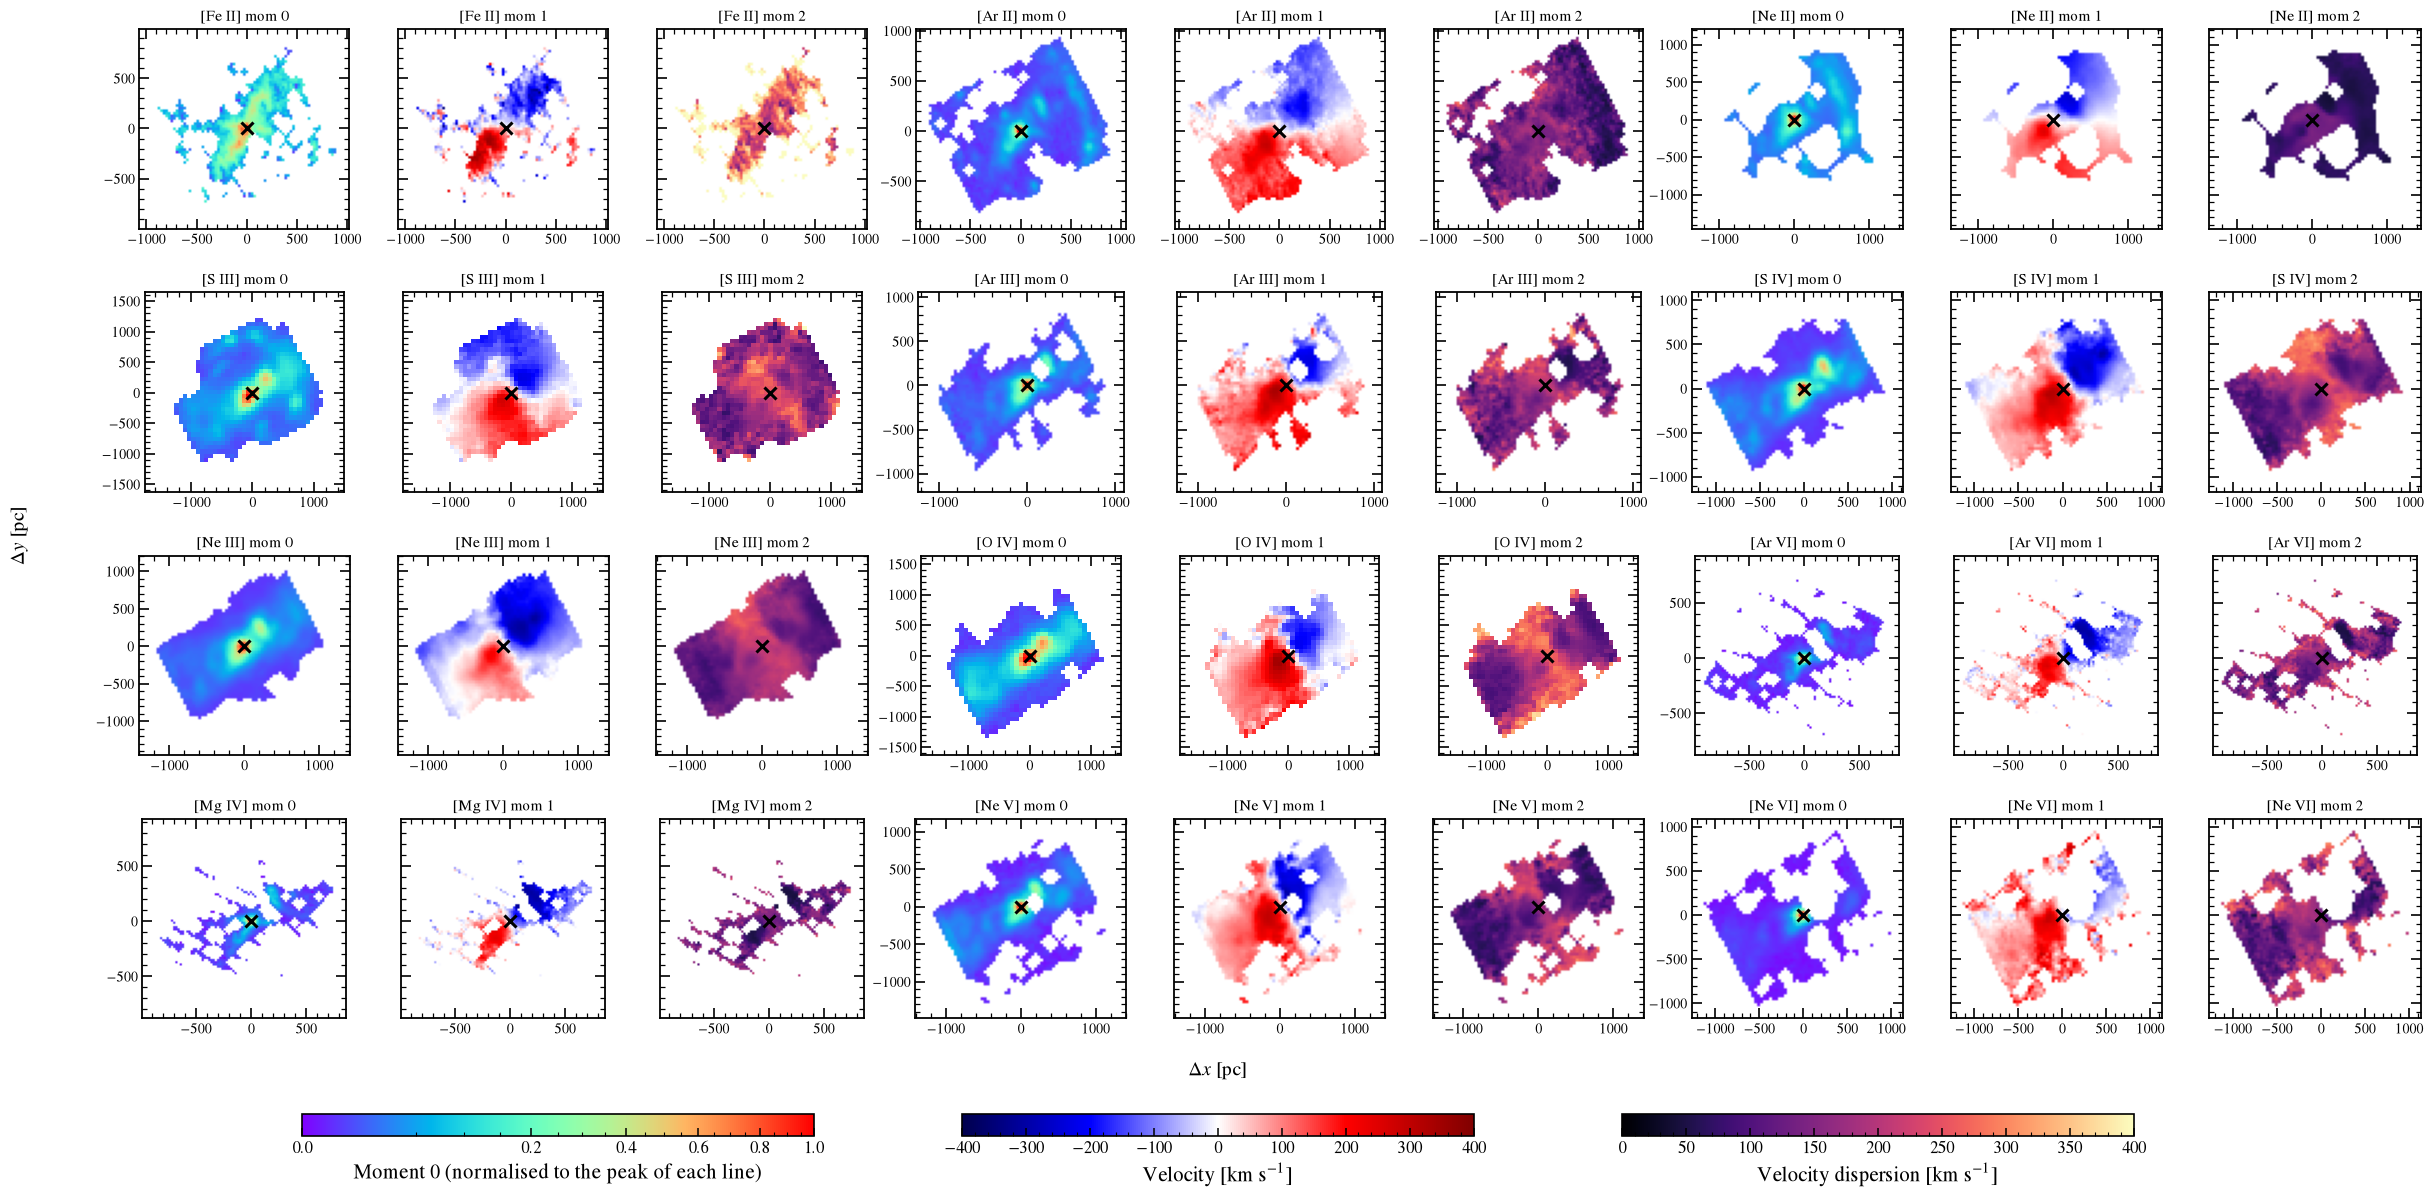

In [18]:
fig = bplt.plot_line_quantities(line_maps, ("mom0", "mom1", "mom2")); proj.savefig(fig, "moment_maps")

### Velocity dispersion of each component (paper Fig. S3)

Enforcing $\sigma_{\rm outflow} > \sigma_{\rm disc}$ in each spaxel, the medians of the two distributions are the
candidate fixed dispersions for Step 3. `SIGMA_OVERRIDES` replaces measured values (the published Table 1 values
are given for comparison).

    line     IP         sigma_disc      sigma_outflow     N
 [Fe II]    7.9     76 +  46/-  30    146 + 105/-  50   972
 [Ar II]   15.8     50 +  31/-  11    106 +  62/-  46  2217
 [Ne II]   21.6     50 +  21/-   6    113 +  24/-  30   834
 [S III]   23.3     69 +  17/-   7    207 +  72/-  87   758
[Ar III]   27.6     58 +  41/-  13    137 +  68/-  58  1202
  [S IV]   34.9     71 +  55/-  21    162 +  52/-  49  1540
[Ne III]   41.0     71 +  30/-  11    190 +  39/-  58  1528
  [O IV]   54.9     82 +  48/-  16    176 +  64/-  52   678
 [Ar VI]   74.8     50 +  32/-  20    104 +  78/-  45  1177
 [Mg IV]   80.1     67 +  43/-  30    138 + 124/-  61   784
  [Ne V]   97.2     63 +  55/-  13    145 +  50/-  49  1362
 [Ne VI]  126.2     56 +  40/-  19    124 +  60/-  49  1077


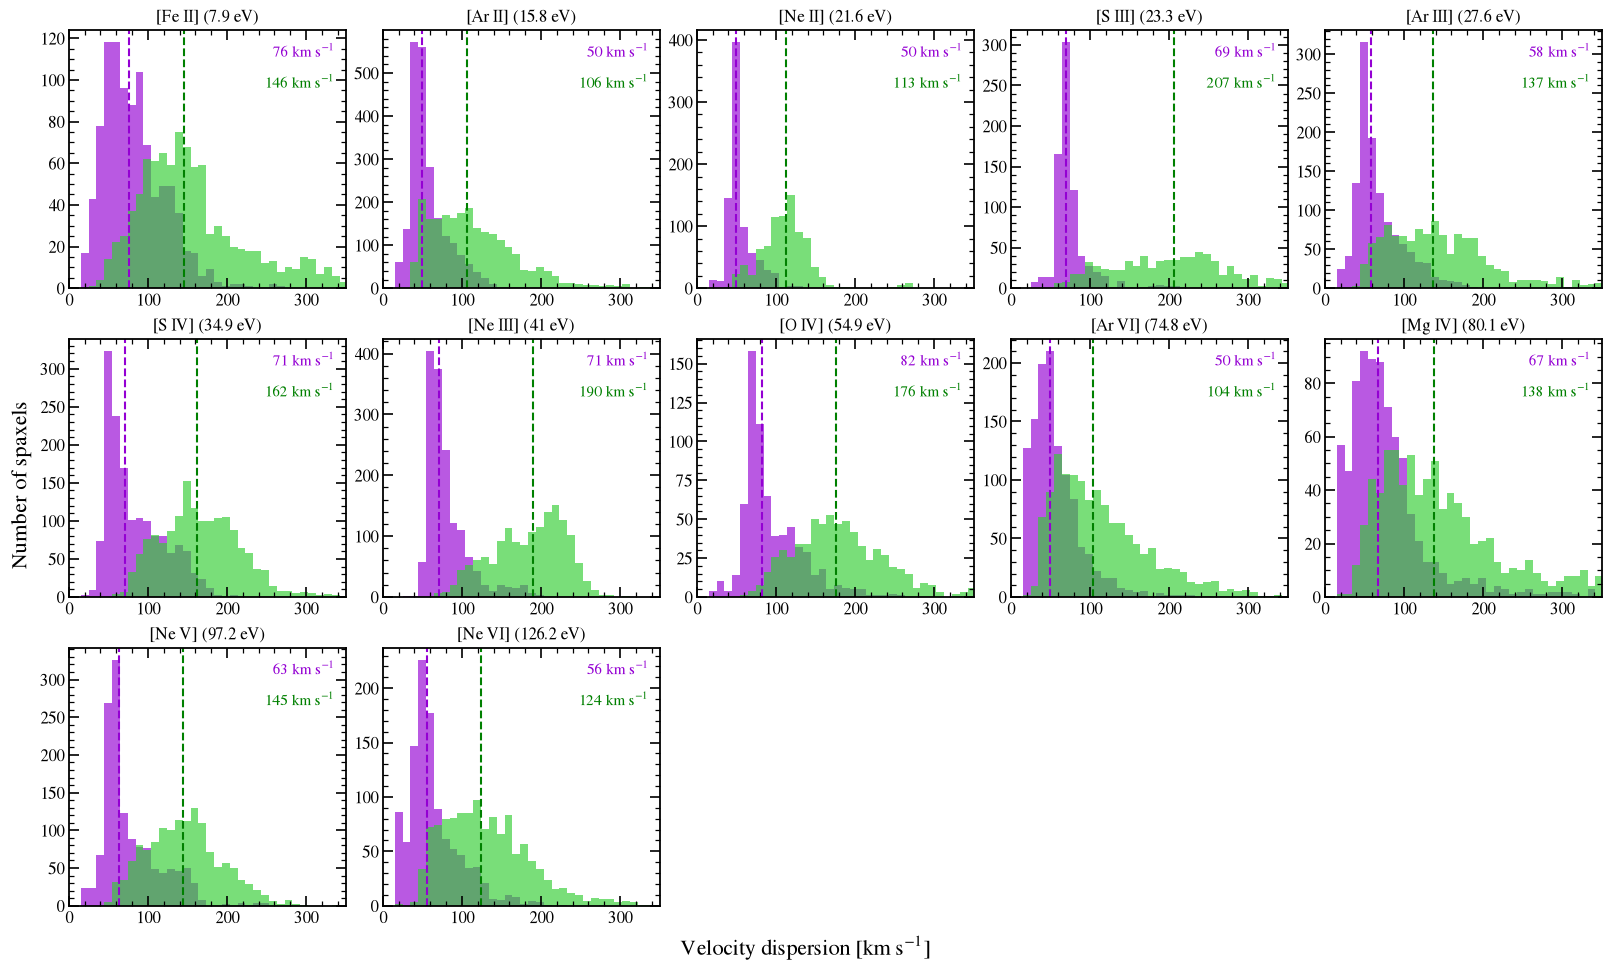

In [20]:
TABLE1_SIGMAS = {"FeII": (78, 203), "ArII": (59, 159), "NeII": (55, 134), "SIII": (72, 175),
                 "ArIII": (67, 163), "SIV": (80, 193), "NeIII": (72, 194), "OIV": (81, 176),
                 "ArVI": (51, 139), "MgIV": (71, 197)}
SIGMA_OVERRIDES = {}                 # e.g. TABLE1_SIGMAS

sigmas_measured = btb.dispersion_medians(line_maps, sigma_range=(15, 600), overrides=SIGMA_OVERRIDES)
fig = bplt.plot_dispersion_histograms(line_maps, sigmas_measured)
proj.savefig(fig, "S3_dispersion_histograms")
proj.save_config(sigmas_measured=sigmas_measured)

## 4. Step 2 - kinematic models

Two components, evaluated at offsets from the AGN in **pc** (angles in degrees, PA east of north):

* **thin rotating disc**: $v = v_{\rm sys} + v_{\rm disc}\tanh(R/R_{\rm disc})\sin i_{\rm disc}\cos\theta$
  - parameters `v_disc`, `R_disc`, `inc_disc`, `pa_disc` (receding side);
* **hollow bicone**: radial velocity rising linearly to `v_out` at `R_out`, falling to 0 at 2`R_out`, inside opening
  angles `theta_in`-`theta_out` around an axis with `inc_out`, `pa_out` (redshifted cone);
* **combined**: $v = \alpha\,v_{\rm disc} + (1-\alpha)\,v_{\rm outflow}$ (`alpha`); plus `v_sys`.

### How to fix or fit each parameter

All parameters live in **one dict**, `MODEL_PARAMS`. For each entry:

* a **number** -> the parameter is **fixed** to that value;
* a **tuple `(lo, hi)`** -> the parameter is **fitted**, with a uniform prior between `lo` and `hi`.

Any combination is allowed - e.g. to fit the disc inclination replace `43.0` by `(20, 70)`; to fix the outflow
speed replace `(100, 1500)` by `700`. The same dict is used for every fit below (a disc-only fit simply ignores
the outflow entries). `init` (optional) narrows where the MCMC walkers start without changing the priors.
For NGC 5728 the geometry is fixed to literature values because the JWST field covers only part of the ring.

In [22]:
MODEL_PARAMS = {
    # ---- systemic velocity ------------------------------------------------------------------
    "v_sys":     0.0,           # km/s   (0 if the redshift is right)
    # ---- disc ----------------------------------------------------------------------------------
    "inc_disc":  43.0,          # deg    Shimizu et al. (2019)       e.g. (20, 70) to fit
    "pa_disc":   194.0,         # deg E of N, Shimizu et al. (2019) e.g. (150, 240) to fit
    "v_disc":    (50, 800),     # km/s   maximum rotation speed
    "R_disc":    (20, 1500),    # pc     turnover radius of the tanh rotation curve
    # ---- outflow (bicone) ----------------------------------------------------------------------
    "inc_out":   48.0,          # deg    Shimizu et al. (2019)
    "pa_out":    110.0,         # deg E of N
    "v_out":     (100, 1500),   # km/s   peak radial outflow speed
    "R_out":     (50, 3000),    # pc     radius of the peak
    "theta_in":  (0, 60),       # deg    inner opening angle
    "theta_out": (30, 120),     # deg    outer opening angle
    # ---- combined model -----------------------------------------------------------------------
    "alpha":     (0, 1),        # disc weight of the velocity
}

DISC_LINES      = ["FeII", "ArII", "NeII"]                 # disc-dominated (low IP)
OUTFLOW_LINES   = ["OIV", "ArVI", "MgIV", "NeV", "NeVI"]   # outflow-dominated (high IP)
DECOMPOSE_LINES = ["FeII", "ArII", "NeII", "SIII", "ArIII", "SIV", "NeIII", "OIV", "ArVI", "MgIV"]
# [Ne V] and [Ne VI] show no disc component in NGC 5728 -> they only constrain the outflow

# For the geometry schematics only: which side of the disc minor axis is nearer to us
# (+1: the side at PA_disc + 90 deg, -1: PA_disc - 90 deg). Not constrained by the velocity field.
DISC_NEAR_SIDE = +1

RUN_KINEMATIC_FITS = True      # False -> skip the fits (Step 3 can still use fixed values)

The fitting sequence: (1) disc-only fits to disc-dominated lines, (2) outflow-only fits to outflow-dominated lines,
(3) combined fits to all decomposable lines started near (1) and (2), (4) averages of IP-independent parameters and
linear trends with IP of those that vary ($R_{\rm out}$, $\alpha$).

  sigma_v (residual scatter) = 166.7 km/s


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20000/20000 [00:16<00:00, 1196.17it/s]


[Fe II] (IP=7.9 eV) - disc model, emcee
      v_sys =      0.00  (fixed)
     v_disc =    319.82  +20.14 / -18.39
     R_disc =    190.05  +53.00 / -44.14
   inc_disc =     43.00  (fixed)
    pa_disc =    194.00  (fixed)
  mean |residual| = 115.8 km/s
  sigma_v (residual scatter) = 68.2 km/s


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20000/20000 [00:22<00:00, 893.02it/s]


[Ar II] (IP=15.8 eV) - disc model, emcee
      v_sys =      0.00  (fixed)
     v_disc =    304.13  +4.41 / -4.34
     R_disc =    189.95  +13.17 / -13.07
   inc_disc =     43.00  (fixed)
    pa_disc =    194.00  (fixed)
  mean |residual| = 46.1 km/s
  sigma_v (residual scatter) = 72.3 km/s


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20000/20000 [00:15<00:00, 1260.88it/s]


[Ne II] (IP=21.6 eV) - disc model, emcee
      v_sys =      0.00  (fixed)
     v_disc =    305.16  +13.03 / -12.17
     R_disc =    414.34  +57.61 / -51.04
   inc_disc =     43.00  (fixed)
    pa_disc =    194.00  (fixed)
  mean |residual| = 50.7 km/s
[NGC5728] 'step2a_disc_fits' done in 58 s
saved -> results/NGC5728/step2a_disc_fits.pkl


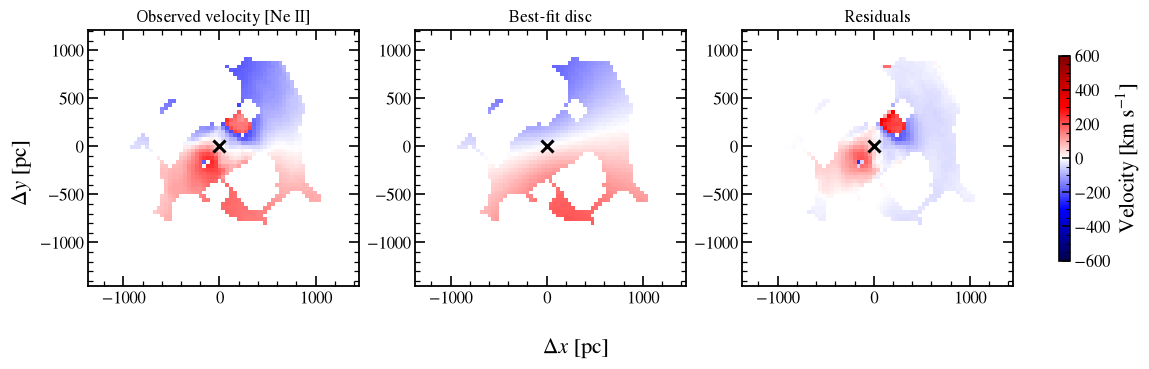

In [24]:
if RUN_KINEMATIC_FITS:
    disc_fits = proj.checkpoint("step2a_disc_fits", btb.fit_many, line_maps, DISC_LINES, "disc",
                                params=MODEL_PARAMS, **MCMC, rerun=RERUN_KINEMATICS,
                                settings=dict(lines=DISC_LINES, params=MODEL_PARAMS, **MCMC))
    fig = bplt.plot_kinematic_fit(disc_fits["NeII"], line_maps["NeII"]);  proj.savefig(fig, "disc_fit_NeII")

  sigma_v (residual scatter) = 85.9 km/s


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20000/20000 [00:21<00:00, 928.69it/s]


[O IV] (IP=54.9 eV) - outflow model, emcee
      v_sys =      0.00  (fixed)
      v_out =    342.96  +18.64 / -18.09
      R_out =    449.36  +19.82 / -16.38
    inc_out =     48.00  (fixed)
     pa_out =    110.00  (fixed)
   theta_in =     21.81  +13.77 / -14.93
  theta_out =    102.23  +12.12 / -12.13
  mean |residual| = 81.8 km/s
  sigma_v (residual scatter) = 138.1 km/s


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20000/20000 [00:26<00:00, 747.15it/s]


[Ar VI] (IP=74.8 eV) - outflow model, emcee
      v_sys =      0.00  (fixed)
      v_out =    202.67  +22.45 / -11.12
      R_out =    391.64  +14.40 / -17.54
    inc_out =     48.00  (fixed)
     pa_out =    110.00  (fixed)
   theta_in =     20.68  +14.19 / -14.09
  theta_out =     81.02  +23.62 / -4.78
  mean |residual| = 98.4 km/s
  sigma_v (residual scatter) = 147.0 km/s


...

[Mg IV] (IP=80.1 eV) - outflow model, emcee
      v_sys =      0.00  (fixed)
      v_out =    143.99  +12.06 / -11.52
      R_out =    524.23  +40.77 / -35.39
    inc_out =     48.00  (fixed)
     pa_out =    110.00  (fixed)
   theta_in =     21.86  +13.26 / -14.69
  theta_out =     91.83  +20.57 / -23.13
  mean |residual| = 112.9 km/s
  sigma_v (residual scatter) = 116.4 km/s


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20000/20000 [00:25<00:00, 789.86it/s]


[Ne V] (IP=97.2 eV) - outflow model, emcee
      v_sys =      0.00  (fixed)
      v_out =    267.07  +17.58 / -13.41
      R_out =    458.70  +24.37 / -16.26
    inc_out =     48.00  (fixed)
     pa_out =    110.00  (fixed)
   theta_in =     21.55  +15.18 / -14.40
  theta_out =    101.32  +12.85 / -11.38
  mean |residual| = 83.3 km/s
  sigma_v (residual scatter) = 102.6 km/s


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20000/20000 [00:24<00:00, 821.71it/s]


[Ne VI] (IP=126.2 eV) - outflow model, emcee
      v_sys =      0.00  (fixed)
      v_out =    286.88  +51.06 / -70.71
      R_out =    328.04  +95.80 / -52.50
    inc_out =     48.00  (fixed)
     pa_out =    110.00  (fixed)
   theta_in =     21.43  +14.02 / -14.50
  theta_out =     98.83  +14.39 / -14.35
  mean |residual| = 75.4 km/s
[NGC5728] 'step2b_outflow_fits' done in 121 s
saved -> results/NGC5728/step2b_outflow_fits.pkl


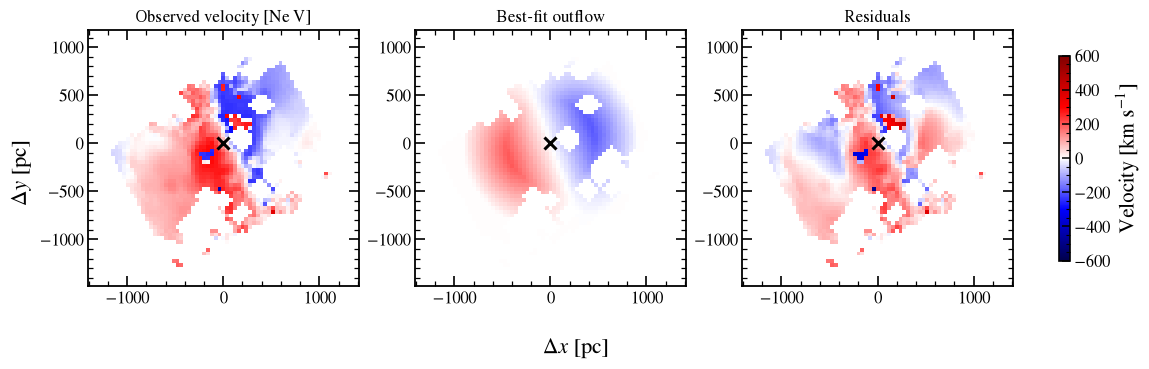

In [25]:
if RUN_KINEMATIC_FITS:
    outflow_fits = proj.checkpoint("step2b_outflow_fits", btb.fit_many, line_maps, OUTFLOW_LINES, "outflow",
                                   params=MODEL_PARAMS, **MCMC, rerun=RERUN_KINEMATICS,
                                   settings=dict(lines=OUTFLOW_LINES, params=MODEL_PARAMS, **MCMC))
    fig = bplt.plot_kinematic_fit(outflow_fits["NeV"], line_maps["NeV"]);  proj.savefig(fig, "outflow_fit_NeV")

   v_disc =    309.7 +/- 7.2  (N=3)
   R_disc =    264.8 +/- 105.8  (N=3)
    v_out =    248.7 +/- 68.9  (N=5)
    R_out =    430.4 +/- 66.2  (N=5)
 theta_in =     21.5 +/- 0.4  (N=5)
theta_out =     95.0 +/- 7.9  (N=5)
  sigma_v (residual scatter) = 148.1 km/s


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20000/20000 [00:31<00:00, 637.72it/s]


[Fe II] (IP=7.9 eV) - combined model, emcee
      v_sys =      0.00  (fixed)
     v_disc =    424.46  +205.73 / -98.88
     R_disc =    134.41  +44.76 / -37.99
   inc_disc =     43.00  (fixed)
    pa_disc =    194.00  (fixed)
      v_out =    627.94  +462.67 / -201.91
      R_out =    360.53  +12.62 / -13.38
    inc_out =     48.00  (fixed)
     pa_out =    110.00  (fixed)
   theta_in =     20.61  +14.16 / -13.92
  theta_out =     57.64  +1.63 / -0.71
      alpha =      0.59  +0.17 / -0.19
  mean |residual| = 92.7 km/s
  sigma_v (residual scatter) = 50.0 km/s


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20000/20000 [00:46<00:00, 431.13it/s]


[Ar II] (IP=15.8 eV) - combined model, emcee
      v_sys =      0.00  (fixed)
     v_disc =    450.65  +198.75 / -89.54
     R_disc =    199.32  +10.56 / -10.50
   inc_disc =     43.00  (fixed)
    pa_disc =    194.00  (fixed)
      v_out =    552.59  +466.50 / -200.72
      R_out =    299.19  +4.69 / -5.61
    inc_out =     48.00  (fixed)
     pa_out =    110.00  (fixed)
   theta_in =     21.03  +14.16 / -14.35
  theta_out =     62.18  +1.68 / -0.13
      alpha =      0.65  +0.16 / -0.20
  mean |residual| = 32.9 km/s
  sigma_v (residual scatter) = 64.8 km/s


...

[O IV] (IP=54.9 eV) - combined model, emcee
      v_sys =      0.00  (fixed)
     v_disc =    394.64  +211.00 / -99.97
     R_disc =    529.54  +164.24 / -165.03
   inc_disc =     43.00  (fixed)
    pa_disc =    194.00  (fixed)
      v_out =    751.44  +412.69 / -207.92
      R_out =    401.39  +7.80 / -8.50
    inc_out =     48.00  (fixed)
     pa_out =    110.00  (fixed)
   theta_in =     20.27  +14.52 / -13.77
  theta_out =    103.05  +11.44 / -11.56
      alpha =      0.52  +0.17 / -0.18
  mean |residual| = 57.0 km/s
  sigma_v (residual scatter) = 135.4 km/s


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20000/20000 [00:28<00:00, 712.99it/s]


[Ar VI] (IP=74.8 eV) - combined model, emcee
      v_sys =      0.00  (fixed)
     v_disc =    164.36  +311.01 / -94.42
     R_disc =    126.57  +827.29 / -82.11
   inc_disc =     43.00  (fixed)
    pa_disc =    194.00  (fixed)
      v_out =    254.32  +200.78 / -43.88
      R_out =    392.47  +12.70 / -11.40
    inc_out =     48.00  (fixed)
     pa_out =    110.00  (fixed)
   theta_in =     21.33  +14.05 / -14.42
  theta_out =     79.27  +16.90 / -4.30
      alpha =      0.23  +0.34 / -0.16
  mean |residual| = 97.5 km/s
  sigma_v (residual scatter) = 145.0 km/s


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20000/20000 [00:24<00:00, 832.09it/s]


[Mg IV] (IP=80.1 eV) - combined model, emcee
      v_sys =      0.00  (fixed)
     v_disc =    218.28  +253.56 / -120.88
     R_disc =    938.75  +394.95 / -604.70
   inc_disc =     43.00  (fixed)
    pa_disc =    194.00  (fixed)
      v_out =    244.91  +368.32 / -81.45
      R_out =    535.37  +49.00 / -37.74
    inc_out =     48.00  (fixed)
     pa_out =    110.00  (fixed)
   theta_in =     21.03  +14.71 / -14.54
  theta_out =     92.98  +18.61 / -22.39
      alpha =      0.43  +0.34 / -0.27
  mean |residual| = 112.6 km/s
[NGC5728] 'step2c_combined_fits' done in 317 s
saved -> results/NGC5728/step2c_combined_fits.pkl
     line     IP           v_disc           R_disc            v_out            R_out         theta_in        theta_out            alpha
  [Fe II]    7.9    424.5 +/-152.3    134.4 +/- 41.4    627.9 +/-332.3    360.5 +/- 13.0     20.6 +/- 14.0     57.6 +/-  1.2      0.6 +/-  0.2
  [Ar II]   15.8    450.7 +/-144.1    199.3 +/- 10.5    552.6 +/-333.6    299.2 +/-  5.1     

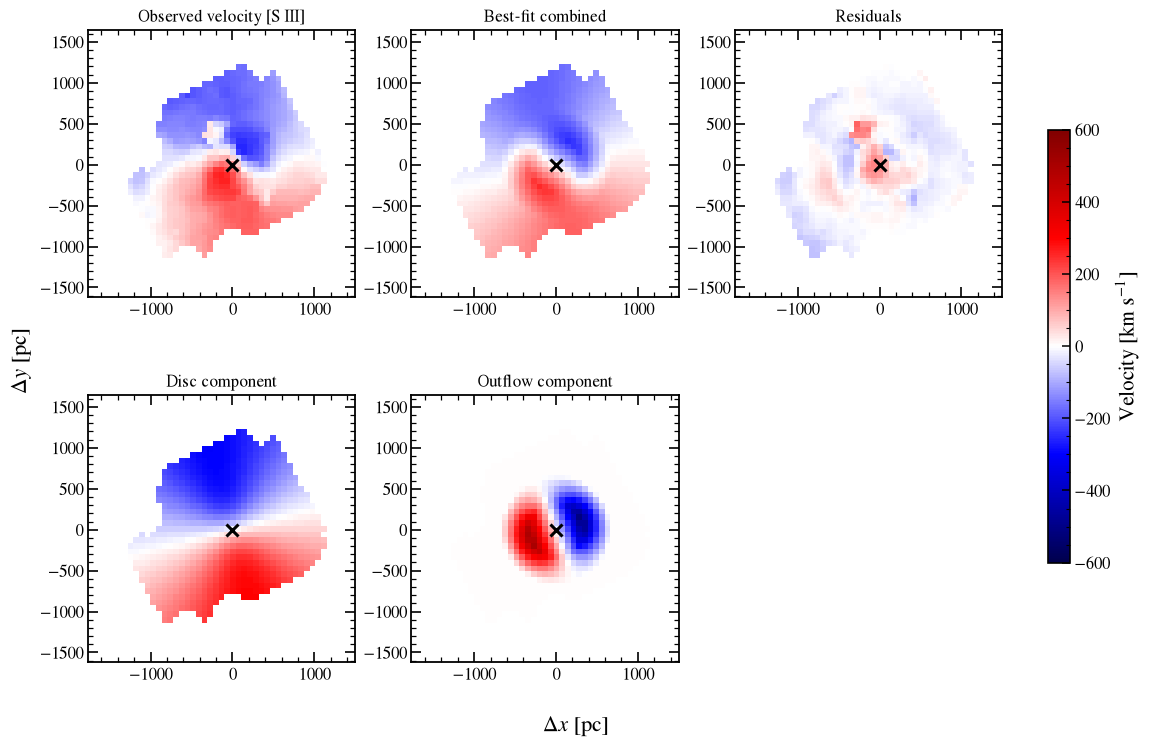

In [26]:
if RUN_KINEMATIC_FITS:
    start = {**btb.mean_params(disc_fits, [k for k in ("v_disc", "R_disc") if not np.isscalar(MODEL_PARAMS[k])]),
             **btb.mean_params(outflow_fits, [k for k in ("v_out", "R_out", "theta_in", "theta_out")
                                              if not np.isscalar(MODEL_PARAMS[k])])}
    init = {k: (0.7 * v, 1.3 * v + 1) for k, v in start.items()}
    combined_fits = proj.checkpoint("step2c_combined_fits", btb.fit_many, line_maps, DECOMPOSE_LINES,
                                    "combined", params=MODEL_PARAMS, init=init, **MCMC, rerun=RERUN_KINEMATICS,
                                    settings=dict(lines=DECOMPOSE_LINES, params=MODEL_PARAMS, init=init, **MCMC))
    btb.fits_table(combined_fits)
    fig = bplt.plot_kinematic_fit(combined_fits["SIII"], line_maps["SIII"]); proj.savefig(fig, "S4_SIII_kinematic_fit")

Parameters against IP. Boxes show the 25-75th percentiles of each posterior, whiskers the 16-84th, the black line
the median (`style="errorbar"` for error bars).

   v_disc =    405.5 +/- 121.6  (N=10)
   R_disc =    481.9 +/- 329.3  (N=10)
    v_out =    586.8 +/- 213.8  (N=10)
 theta_in =     20.9 +/- 0.4  (N=10)
theta_out =     90.3 +/- 16.8  (N=10)
R_out = 1.773 * IP + 277.44
alpha = -0.004 * IP + 0.74


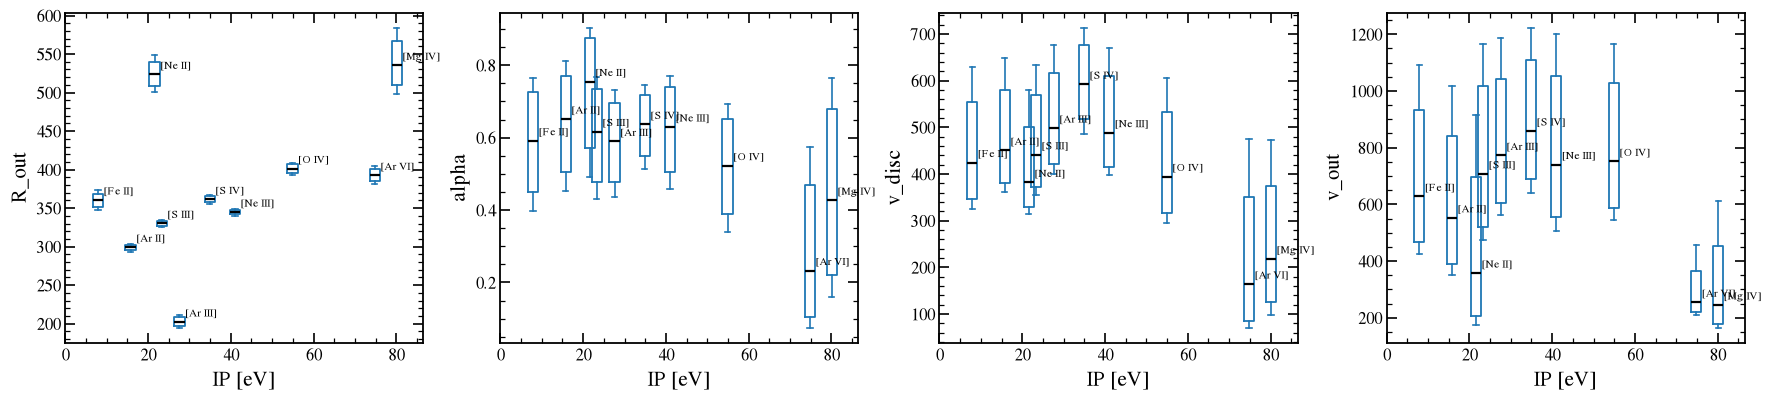

In [28]:
if RUN_KINEMATIC_FITS:
    fig = bplt.plot_params_vs_ip(combined_fits, ["R_out", "alpha", "v_disc", "v_out"], style="box")
    proj.savefig(fig, "params_vs_IP")
    FIT_MEANS = btb.mean_params(combined_fits, ["v_disc", "R_disc", "v_out", "theta_in", "theta_out"])
    R_OUT_TREND = btb.trend_with_ip(combined_fits, "R_out")
    ALPHA_TREND = btb.trend_with_ip(combined_fits, "alpha", max_ip=81)

**Best-fit geometry.** Schematic of the disc and bicone from the combined fits (geometry and opening angles averaged
over the lines; cones drawn out to 2 $R_{\rm out}$). Left: as seen by the observer - parts of the cones behind the disc are
drawn as a wire-frame, parts in front are shaded, and the yellow lines mark where the cones cross the disc plane.
Right: a 3-D view with the line of sight marked. `DISC_NEAR_SIDE` (above) flips which side of the disc is nearer to us.

disc:   inc = 43.0 deg, PA = 194.0 deg (receding side)
bicone: inc = 48.0 deg from the line of sight (42.0 deg from the sky plane), PA = 110.0 deg (redshifted cone), theta_in/out = 20.9/90.3 deg
  drawn with theta_out/2: theta_in/out = 20.9/45.2 deg
angle between the bicone axis and the disc normal: 89.2 deg (depends on disc_near_side = +1)


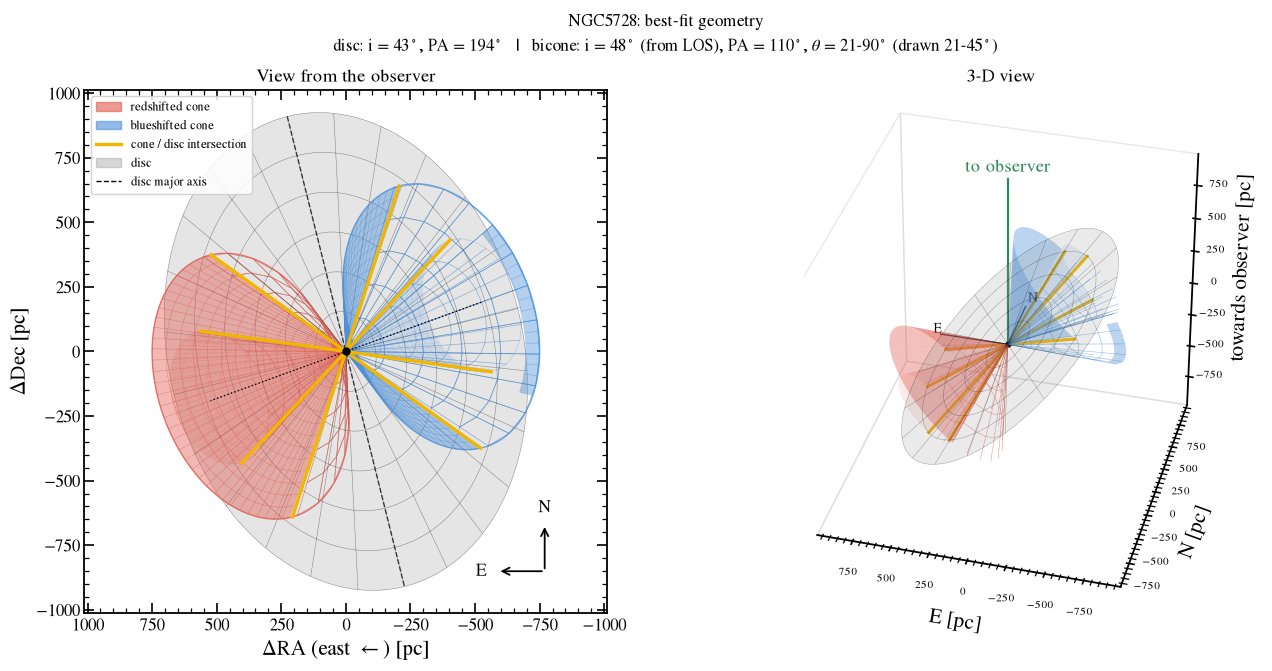

In [30]:
if RUN_KINEMATIC_FITS:
    FIT_GEOMETRY = btb.mean_geometry(combined_fits)
    fig = btb.plot_geometry(FIT_GEOMETRY, disc_near_side=DISC_NEAR_SIDE, title=f"{GALAXY}: best-fit geometry")
    proj.savefig(fig, "geometry_best_fit")

### Optional: velocity / dispersion maps from other codes (3DBarolo, MOKA3D, ...)

Instead of the built-in models, any component can use a map produced elsewhere, e.g. a disc velocity (and
dispersion) field from **3DBarolo** or an outflow velocity field from **MOKA3D**. Give the AGN pixel position *in that
map*, its pixel size, and the systemic velocity to subtract if it holds absolute velocities; the map is then
re-projected onto every line's grid like the models. Where an imported map is undefined the built-in model (or
fixed dispersion) is used. Keys: `"v_disc"`, `"v_out"`, `"sigma_disc"`, `"sigma_out"`. Off by default.

In [32]:
USE_EXTERNAL_MAPS = False
EXTERNAL = {}

if USE_EXTERNAL_MAPS:
    pc_scale = next(iter(cubes.values())).pc_per_arcsec           # pc per arcsec
    EXTERNAL["v_disc"] = btb.load_external_map("path/to/3dbarolo_model_velocity.fits",
                                               agn_xy=(40.0, 40.0),      # AGN / kinematic centre in that map
                                               pixel_scale_arcsec=0.2, pc_per_arcsec=pc_scale,
                                               subtract=0.0)             # systemic velocity if absolute
    # EXTERNAL["sigma_disc"] = btb.load_external_map("path/to/3dbarolo_model_dispersion.fits", ...)
    # EXTERNAL["v_out"]      = btb.load_external_map("path/to/moka3d_velocity_map.fits", ...)

    # check the alignment against an observed velocity map
    lm = line_maps["NeII"]
    fig = bplt.plot_velocity_panels({"observed": lm.velocity_map(),
                                     "imported disc": np.where(lm.good, EXTERNAL["v_disc"].on_grid(lm), np.nan)},
                                    lm.extent_pc(), vlim=400)
    proj.savefig(fig, "external_map_check")

## 5. Step 3 - Breaking the blend: constrained decomposition per spaxel

In each good spaxel every decomposable line is fitted with two Gaussians whose **centroids are fixed** to the disc
and outflow velocities and whose **dispersions are fixed**, so only the two amplitudes are free (non-negative
least squares): $f_{\rm disc} = A_{\rm disc}\sigma_{\rm disc} / (A_{\rm disc}\sigma_{\rm disc} + A_{\rm out}\sigma_{\rm out})$.

### Which model parameters and dispersions to use

`DECOMP_PARAMS` selects the model parameters of each line:

* `"fixed_per_line"` - `FIXED_LINE_PARAMS`: one set per line (here the per-line best fits of the original NGC 5728
  analysis; radii in pixels of each line's cube, converted to pc below);
* `"fixed_common"` - `FIXED_COMMON` for all lines plus $R_{\rm out}(IP)$ from `FIXED_R_OUT`
  (here the averaged values and trend of the original analysis);
* `"fit_mean"` - the geometry plus the averages of the combined fits of Section 4, and the fitted $R_{\rm out}(IP)$;
* `"fit_per_line"` - each line's own combined fit from Section 4.

`DECOMP_SIGMAS` selects the dispersions: `"fixed"` (`FIXED_SIGMAS`, here those of the original analysis) or
`"measured"` (the Step 1 medians).

In [35]:
DECOMP_PARAMS = "fixed_per_line"    # "fixed_per_line" | "fixed_common" | "fit_mean" | "fit_per_line"
DECOMP_SIGMAS = "fixed"             # "fixed" | "measured"

GEOMETRY = {k: MODEL_PARAMS[k] for k in ("v_sys", "inc_disc", "pa_disc", "inc_out", "pa_out")}

# --- per-line values (original NGC 5728 analysis) ---------------------------------------------------------
#                v_disc  R_disc  v_out  R_out   theta_in theta_out     (km/s, PIXELS, km/s, PIXELS, deg, deg)
FIXED_LINE_PARAMS_PIX = {
    "FeII":  (457.6,  7.09, 590.0, 13.13, 21.0,  80.0),
    "ArII":  (420.9,  7.14, 483.6, 14.83, 21.0,  80.0),
    "NeII":  (399.8,  6.93, 528.0,  9.84, 22.3,  90.0),
    "SIII":  (393.0,  4.98, 588.0,  5.51, 21.0,  90.0),
    "ArIII": (444.0, 10.22, 752.0, 11.11, 21.0,  70.0),
    "SIV":   (438.0, 18.70, 697.0, 10.64, 21.0, 102.0),
    "NeIII": (381.0, 11.31, 567.0,  9.39, 21.0,  80.0),
    "OIV":   (337.0,  6.35, 612.0,  6.37, 21.0, 101.0),
    "ArVI":  (294.5,  6.83, 665.0, 15.07, 21.0,  77.0),
    "MgIV":  (202.9, 14.43, 855.0, 11.30, 21.0,  64.0),
}
# --- common values (averages of the original analysis) ----------------------------------------------------
FIXED_COMMON = dict(v_disc=400.0, R_disc=290.0, v_out=700.0, theta_in=21.0, theta_out=80.0)
FIXED_R_OUT  = (3.6, 535.0)                        # R_out = 3.6 * IP + 535 pc
# --- dispersions (sigma_disc, sigma_outflow) [km/s] used in the original decomposition --------------------
FIXED_SIGMAS = {"FeII": (78, 203), "ArII": (59, 159), "NeII": (81, 176), "SIII": (72, 175),
                "ArIII": (67, 163), "SIV": (80, 193), "NeIII": (72, 176), "OIV": (81, 176),
                "ArVI": (51, 139), "MgIV": (71, 197)}
# In the original notebook the flux fractions of these two lines used the Table 1 dispersions while the
# amplitude fit used FIXED_SIGMAS. Kept here to reproduce the published maps; set to {} for the
# self-consistent calculation.
FRACTION_SIGMA_OVERRIDES = {"NeII": (55, 134), "NeIII": (72, 194)}
# Spectra used in the original decomposition: wider windows with a linear continuum. Set to {} to use the
# Step 1 spectra instead.            window (rest um)   line-free outside (rest um)
DECOMP_RECUT = {n: dict(window=w, line_region=lr, cont_order=1) for n, (w, lr) in {
    "FeII": ((5.25, 5.45), (5.33, 5.35)),       "ArII": ((6.90, 7.08), (6.976, 6.993)),
    "NeII": ((12.72, 12.92), (12.785, 12.835)), "SIII": ((18.62, 18.82), (18.680, 18.740)),
    "ArIII": ((8.94, 9.07), (8.975, 9.005)),    "SIV": ((10.43, 10.59), (10.49, 10.53)),
    "NeIII": ((15.45, 15.65), (15.54, 15.59)),  "OIV": ((25.80, 25.98), (25.84, 25.94)),
    "ArVI": ((4.49, 4.59), (4.525, 4.535)),     "MgIV": ((4.42, 4.56), (4.47, 4.50))}.items()}

In [36]:
dmaps = {n: line_maps[n] for n in DECOMPOSE_LINES}
if DECOMP_PARAMS == "fixed_per_line":
    per_line = {n: dict(v_disc=vd, R_disc=rd * dmaps[n].pixel_scale_pc, v_out=vo,
                        R_out=ro * dmaps[n].pixel_scale_pc, theta_in=ti, theta_out=to)
                for n, (vd, rd, vo, ro, ti, to) in FIXED_LINE_PARAMS_PIX.items() if n in dmaps}
    line_parameters = btb.line_params(dmaps, GEOMETRY, per_line=per_line)
elif DECOMP_PARAMS == "fixed_common":
    a, b = FIXED_R_OUT
    line_parameters = btb.line_params(dmaps, {**GEOMETRY, **FIXED_COMMON},
                                      ip_relations={"R_out": lambda ip: a * ip + b})
elif DECOMP_PARAMS == "fit_mean":
    a, b = R_OUT_TREND
    line_parameters = btb.line_params(dmaps, {**GEOMETRY, **FIT_MEANS},
                                      ip_relations={"R_out": lambda ip: a * ip + b})
elif DECOMP_PARAMS == "fit_per_line":
    line_parameters = btb.line_params(dmaps, GEOMETRY, fits=combined_fits)
else:
    raise ValueError(DECOMP_PARAMS)

if DECOMP_SIGMAS == "fixed":
    sigmas = {n: {"disc": FIXED_SIGMAS[n][0], "outflow": FIXED_SIGMAS[n][1]} for n in DECOMPOSE_LINES}
else:
    sigmas = sigmas_measured

proj.save_config(decomp_params_source=DECOMP_PARAMS, decomp_sigmas_source=DECOMP_SIGMAS,
                 decomposition_params=line_parameters, decomposition_sigmas=sigmas)

  [Fe II]: v_disc=457.6, R_disc=183.0, v_out=590.0, R_out=338.9, theta_in=21.0, theta_out=80.0
  [Ar II]: v_disc=420.9, R_disc=184.3, v_out=483.6, R_out=382.8, theta_in=21.0, theta_out=80.0
  [Ne II]: v_disc=399.8, R_disc=275.2, v_out=528.0, R_out=390.8, theta_in=22.3, theta_out=90.0
  [S III]: v_disc=393.0, R_disc=346.1, v_out=588.0, R_out=382.9, theta_in=21.0, theta_out=90.0
 [Ar III]: v_disc=444.0, R_disc=345.0, v_out=752.0, R_out=375.0, theta_in=21.0, theta_out=70.0
   [S IV]: v_disc=438.0, R_disc=631.2, v_out=697.0, R_out=359.2, theta_in=21.0, theta_out=102.0
 [Ne III]: v_disc=381.0, R_disc=449.1, v_out=567.0, R_out=372.9, theta_in=21.0, theta_out=80.0
   [O IV]: v_disc=337.0, R_disc=441.3, v_out=612.0, R_out=442.7, theta_in=21.0, theta_out=101.0
  [Ar VI]: v_disc=294.5, R_disc=135.6, v_out=665.0, R_out=299.2, theta_in=21.0, theta_out=77.0
  [Mg IV]: v_disc=202.9, R_disc=286.5, v_out=855.0, R_out=224.4, theta_in=21.0, theta_out=64.0


In [37]:
DECOMP_OPTIONS = dict(names=DECOMPOSE_LINES, sigma_mode="fixed", recut=DECOMP_RECUT,
                      sigma_fraction=FRACTION_SIGMA_OVERRIDES)

decomps = proj.checkpoint("step3_decompositions", btb.decompose_lines, line_maps, line_parameters, sigmas,
                          cubes=cubes, external=EXTERNAL or None, **DECOMP_OPTIONS, rerun=RERUN_DECOMPOSITION,
                          settings=dict(params=line_parameters, sigmas=sigmas, external=sorted(EXTERNAL),
                                        **DECOMP_OPTIONS))

  FeII:   0%|          | 0/997 [00:00<?, ?it/s]

  -> Decomposition([Fe II], IP=7.9, sigma_disc=78, sigma_out=203, <f_disc>=0.35)


  ArII:   0%|          | 0/2292 [00:00<?, ?it/s]

  -> Decomposition([Ar II], IP=15.8, sigma_disc=59, sigma_out=159, <f_disc>=0.55)


  NeII:   0%|          | 0/851 [00:00<?, ?it/s]

...

  -> Decomposition([O IV], IP=54.9, sigma_disc=81, sigma_out=176, <f_disc>=0.42)


  ArVI:   0%|          | 0/1367 [00:00<?, ?it/s]

  -> Decomposition([Ar VI], IP=74.8, sigma_disc=51, sigma_out=139, <f_disc>=0.30)


  MgIV:   0%|          | 0/864 [00:00<?, ?it/s]

  -> Decomposition([Mg IV], IP=80.1, sigma_disc=71, sigma_out=197, <f_disc>=0.25)
[NGC5728] 'step3_decompositions' done in 1 s
saved -> results/NGC5728/step3_decompositions.pkl


Disc-fraction map of every line (paper Fig. S6):

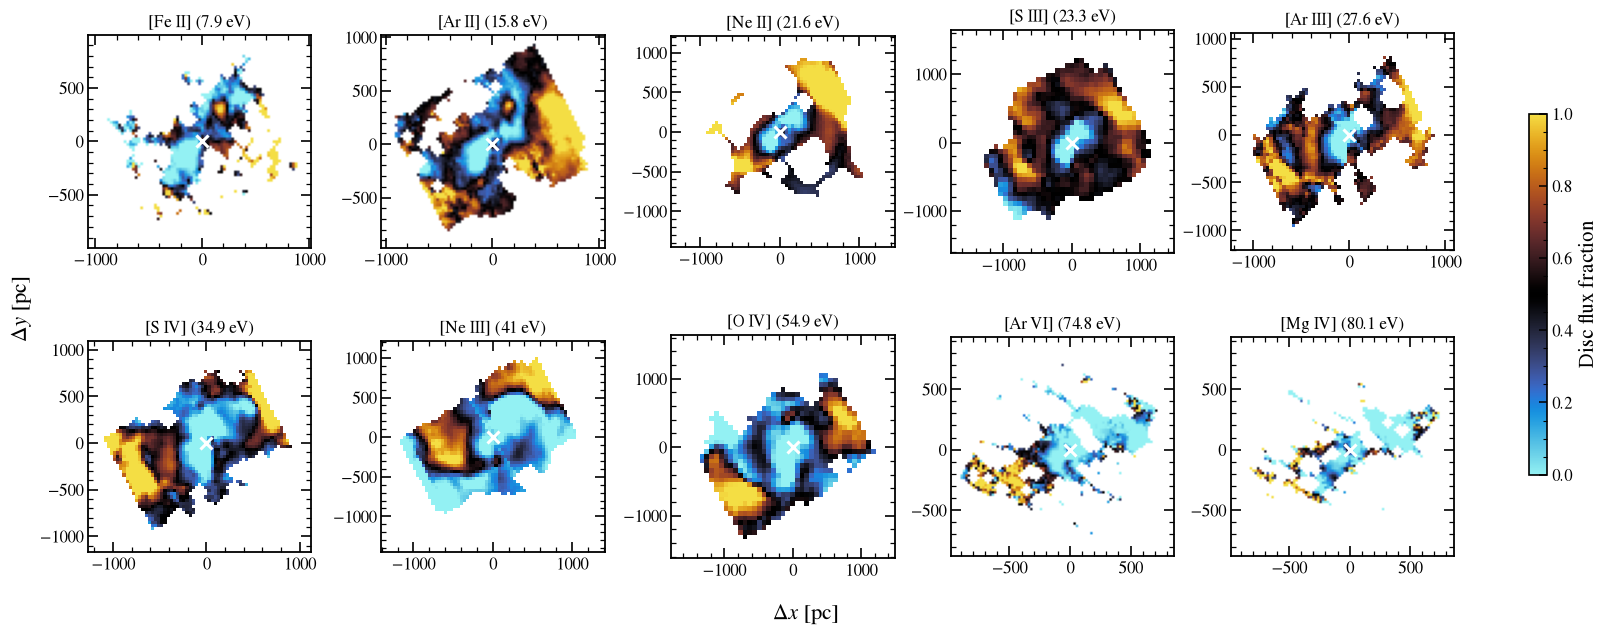

In [39]:
fig = bplt.plot_fraction_maps(decomps, "f_disc");  proj.savefig(fig, "S6_disc_fraction_maps")
# fig = bplt.plot_residual_maps(decomps)          # coherent residuals would point to a missing component
# fig = bplt.plot_decomposition_spaxels(decomps["NeIII"], line_maps["NeIII"])   # individual spaxel fits

## 6. Step 4 - stack all lines into one map (paper Fig. 2)

Each line's $f_{\rm disc}$ map is interpolated onto a common parsec grid centred on the AGN and averaged with a weight
$w = 1 - 2|\langle f_{\rm disc}\rangle - 0.5|$ favouring lines that trace both components. Only points covered by at
least `min_lines` lines are kept.

     line  <f_disc>  weight
  [Fe II]      0.35    0.70
  [Ar II]      0.55    0.90
  [Ne II]      0.63    0.73
  [S III]      0.55    0.91
 [Ar III]      0.57    0.86
   [S IV]      0.47    0.94
 [Ne III]      0.35    0.69
   [O IV]      0.42    0.84
  [Ar VI]      0.30    0.60
  [Mg IV]      0.25    0.51
grid: 305x305 at 9.9 pc; 29079 points with >= 2 lines
line-to-line scatter in f_disc: 0.19
Stacked map: 29079 grid points with a fraction (2.87 kpc^2)
  disc / star-formation dominated (f_out <= 0.2):   6.0 %
  mixed (0.2 < f_out < 0.8):                     86.8 %
  outflow / AGN dominated (f_out >= 0.8):          7.3 %
  mean f_out = 0.50, median f_out = 0.50
saved -> results/NGC5728/step4_stacked_map.pkl
exported -> results/NGC5728/stacked_fraction_map.npz


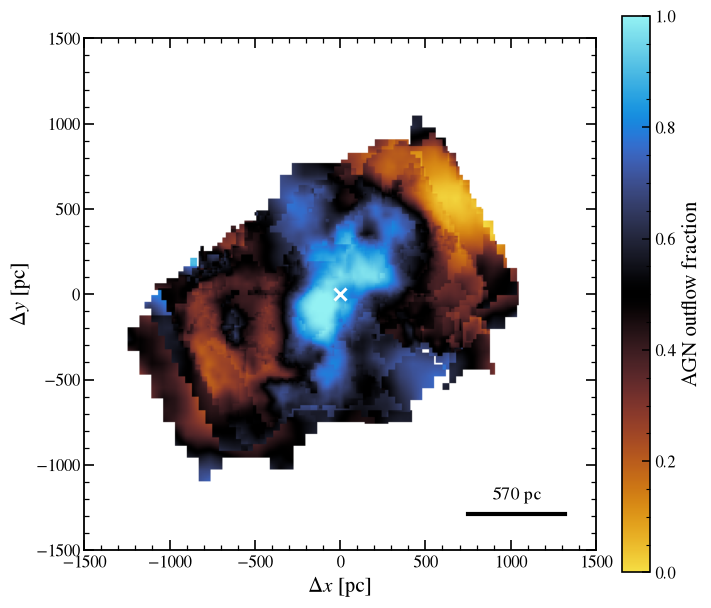

In [41]:
STACK_OPTIONS = dict(scheme="linear", combine="mean", min_lines=2, grid_halfsize_pc=1500)

SF_MAX, AGN_MIN = 0.2, 0.8      # f_out thresholds for disc- / outflow-dominated (also used for the spectra)

stack = btb.stack_fraction_maps(decomps, **STACK_OPTIONS)
print(f"line-to-line scatter in f_disc: {btb.line_to_line_scatter(stack):.2f}")
FRACTIONS = btb.fraction_summary(stack, sf_max=SF_MAX, agn_min=AGN_MIN)
proj.save_config(fraction_summary=FRACTIONS)

fig = bplt.plot_stacked_map(stack, which="f_out", lim_pc=1500, scalebar_pc=570)
proj.savefig(fig, "Fig2_outflow_fraction")
proj.save(stack, "step4_stacked_map")
proj.export_stacked_map(stack)

**Geometry used in the decomposition** (averaged over the decomposed lines - with `DECOMP_PARAMS = "fixed_per_line"`
the opening angles and radii differ from line to line, so this is their mean). If imported maps replaced a component
(Section 4), its drawn geometry is only indicative.

disc:   inc = 43.0 deg, PA = 194.0 deg (receding side)
bicone: inc = 48.0 deg from the line of sight (42.0 deg from the sky plane), PA = 110.0 deg (redshifted cone), theta_in/out = 21.1/83.4 deg
  drawn with theta_out/2: theta_in/out = 21.1/41.7 deg
angle between the bicone axis and the disc normal: 89.2 deg (depends on disc_near_side = +1)


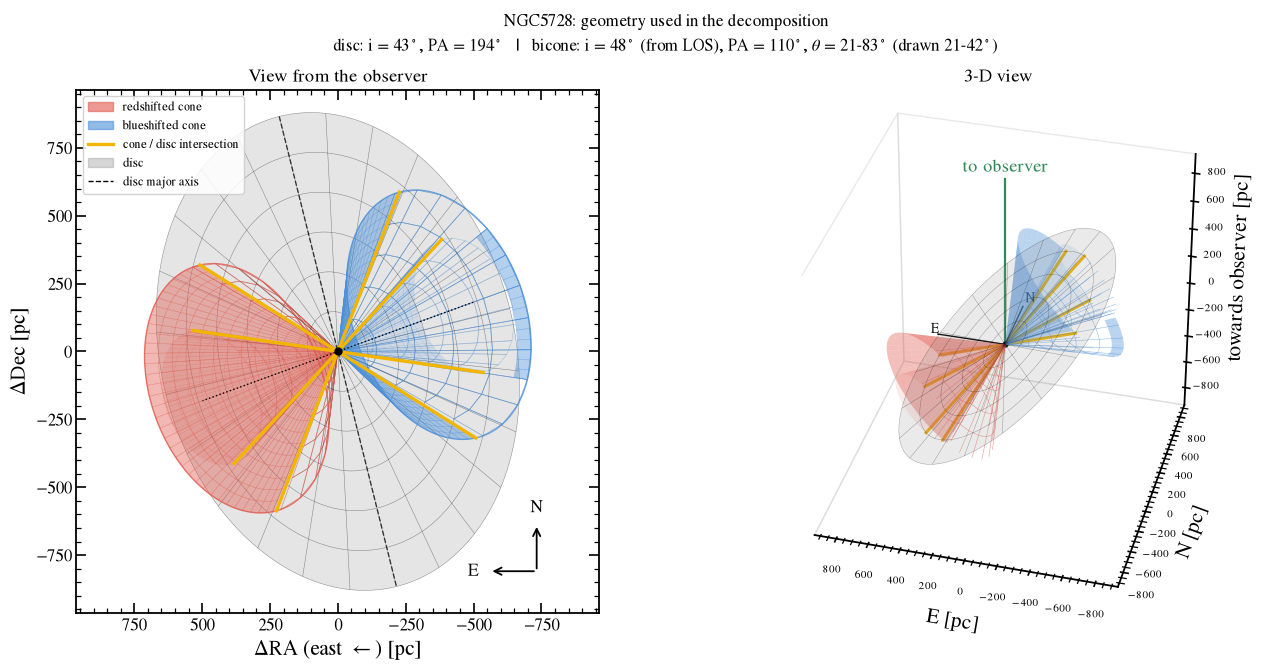

In [43]:
USED_GEOMETRY = btb.mean_geometry(line_parameters)
fig = btb.plot_geometry(USED_GEOMETRY, disc_near_side=DISC_NEAR_SIDE, title=f"{GALAXY}: geometry used in the decomposition")
proj.savefig(fig, "geometry_used")

**Robustness** (paper Sect. 3.4): the map should not depend on the weighting or on any single line.

            equal weights: median |delta f_disc| = 0.010
         gaussian weights: median |delta f_disc| = 0.001
                   median: median |delta f_disc| = 0.030
          without [Fe II]: median |delta f_disc| = 0.000


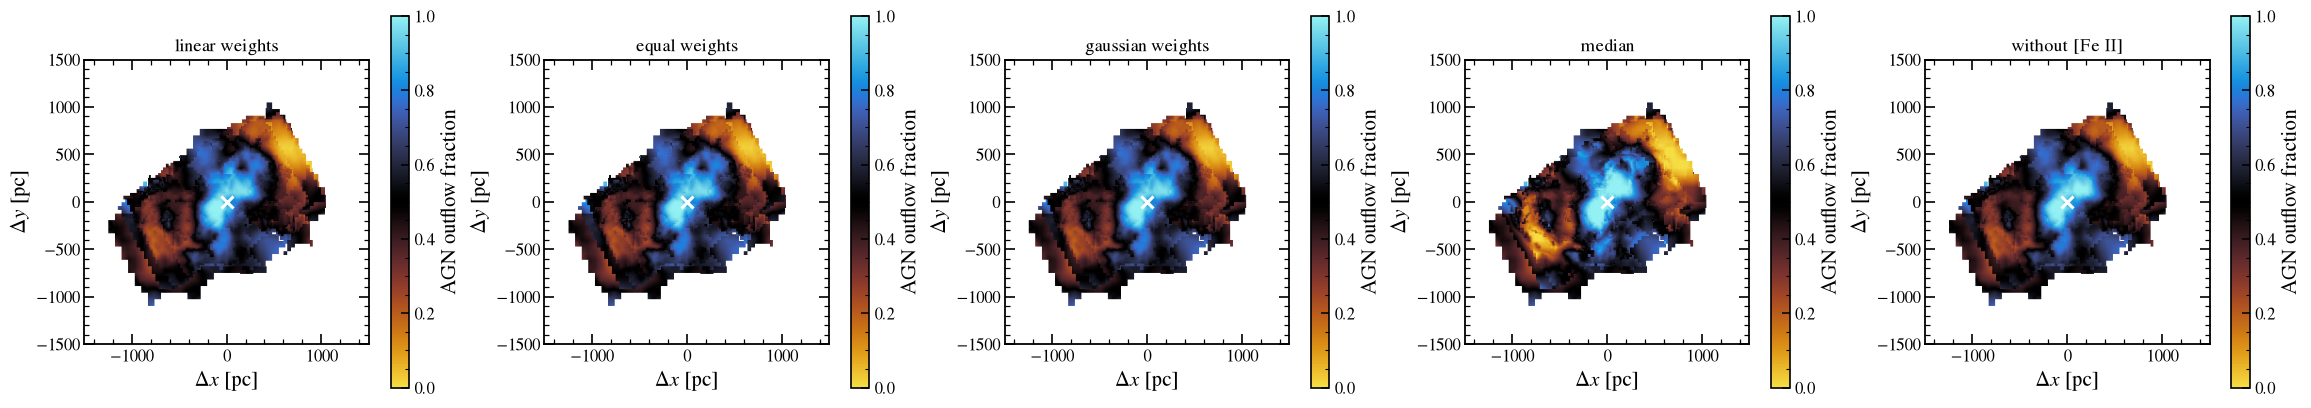

In [45]:
alternatives = {
    "linear weights":   stack,
    "equal weights":    btb.stack_fraction_maps(decomps, **{**STACK_OPTIONS, "scheme": "equal"}, verbose=False),
    "gaussian weights": btb.stack_fraction_maps(decomps, **{**STACK_OPTIONS, "scheme": "gaussian"}, verbose=False),
    "median":           btb.stack_fraction_maps(decomps, **{**STACK_OPTIONS, "combine": "median"}, verbose=False),
    "without [Fe II]":  btb.stack_fraction_maps(decomps, names=[n for n in DECOMPOSE_LINES if n != "FeII"],
                                                **STACK_OPTIONS, verbose=False),
}
btb.compare_stacks(alternatives, "linear weights")

fig, axes = plt.subplots(1, len(alternatives), figsize=(4.6 * len(alternatives), 4.0), constrained_layout=True)
for ax, (k, s) in zip(axes, alternatives.items()):
    bplt.plot_stacked_map(s, lim_pc=1500, ax=ax, title=k)
proj.savefig(fig, "stack_robustness")

## 7. Step 5 - AGN and star-forming spectra

The stacked map is projected onto **every** cube (NIRSpec + all MRS bands). Spaxels with $f_{\rm out} > 0.8$ give
the AGN-dominated spectrum and $f_{\rm out} < 0.2$ the star-formation-dominated one (`method="weighted"` instead
weights every spaxel by its fractions). The per-band spectra are stitched band by band, outwards from a reference band
(by default the one covering the largest sky area, so a small field of view does not set the normalisation). Channels
without data (e.g. the NIRSpec G395H detector gap near 4.1 $\mu$m) are left out, and bands with fewer than
`min_spaxels` selected spaxels are skipped for that component.

**Errors** (third column of the exported `.txt` files, 1$\sigma$ in Jy, shaded in the plot). `ERR_METHOD = "cube"` adds the
pipeline ERR values of the selected spaxels in quadrature. This treats spaxels as independent, so it is a *lower limit*:
neighbouring spaxels of a resampled cube share noise. `"empirical"` measures the channel-to-channel scatter of each
extracted spectrum instead (includes that correlated noise, but is inflated next to strong lines); `"max"` takes the
larger of the two. Errors are scaled with each band during stitching and combined in the overlaps; they do not include
the uncertainty of the band-to-band scale factors, and are per channel (the plotted line may be smoothed).

ComponentSpectra(g395h-f290lp, threshold, N_agn=525, N_sf=62)
ComponentSpectra(ch1-short, threshold, N_agn=307, N_sf=108)
ComponentSpectra(ch1-medium, threshold, N_agn=308, N_sf=93)
ComponentSpectra(ch1-long, threshold, N_agn=308, N_sf=144)
ComponentSpectra(ch2-short, threshold, N_agn=185, N_sf=91)
ComponentSpectra(ch2-medium, threshold, N_agn=181, N_sf=76)
ComponentSpectra(ch2-long, threshold, N_agn=183, N_sf=88)
ComponentSpectra(ch3-short, threshold, N_agn=131, N_sf=99)
ComponentSpectra(ch3-medium, threshold, N_agn=131, N_sf=102)
ComponentSpectra(ch3-long, threshold, N_agn=129, N_sf=102)
ComponentSpectra(ch4-short, threshold, N_agn=41, N_sf=34)
ComponentSpectra(ch4-medium, threshold, N_agn=43, N_sf=36)
ComponentSpectra(ch4-long, threshold, N_agn=41, N_sf=35)


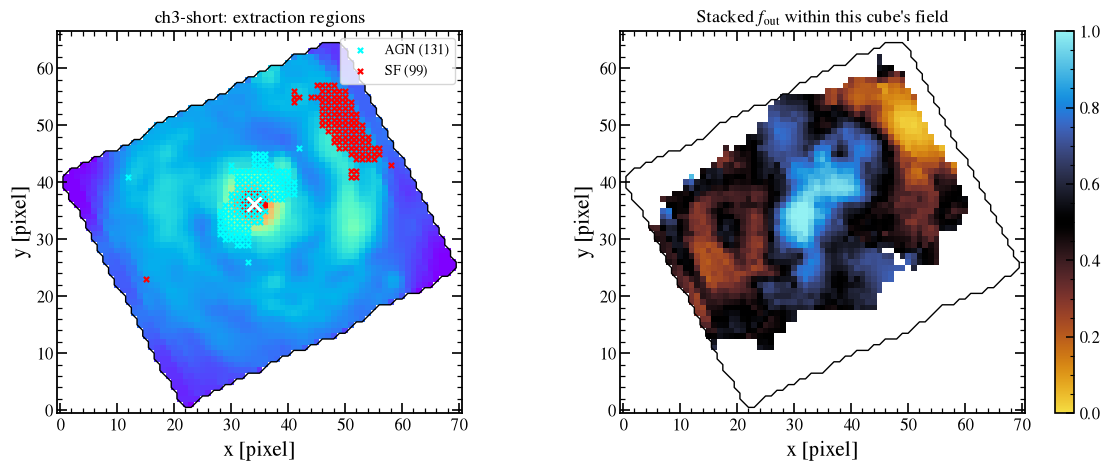

In [47]:
ERR_METHOD = "cube"         # "cube" (ERR extension, quadrature), "empirical" (measured scatter), "max" or None

spectra = btb.extract_all(cubes, stack, method="threshold", agn_min=AGN_MIN, sf_max=SF_MAX, min_spaxels=3,
                          err_method=ERR_METHOD)
fig = bplt.plot_extraction_regions(spectra["ch3-short"], cubes["ch3-short"]);  proj.savefig(fig, "extraction_regions")

ch2-medium: scale = 1.017
ch2-long: scale = 0.974
ch3-short: scale = 0.939
ch3-medium: scale = 0.920
ch3-long: scale = 0.935
ch4-short: scale = 0.945
ch4-medium: scale = 0.918
ch4-long: scale = 0.921
ch1-long: scale = 1.016
ch1-medium: scale = 1.098
ch1-short: scale = 1.122
g395h-f290lp: scale = 0.991
reference band: ch2-short
ch4-long: scale = 0.950
ch4-short: scale = 1.047
ch3-long: scale = 1.078
ch3-medium: scale = 1.056
ch3-short: scale = 1.178
ch2-long: scale = 1.723
ch2-medium: scale = 2.174
ch2-short: scale = 2.335
ch1-long: scale = 2.650
ch1-medium: scale = 3.720
ch1-short: scale = 1.554
g395h-f290lp: scale = 3.640
reference band: ch4-medium
median S/N per channel: AGN 946, SF 129
saved -> results/NGC5728/step5_spectra.pkl
exported -> results/NGC5728/component_spectra_AGN.txt
exported -> results/NGC5728/component_spectra_SF.txt


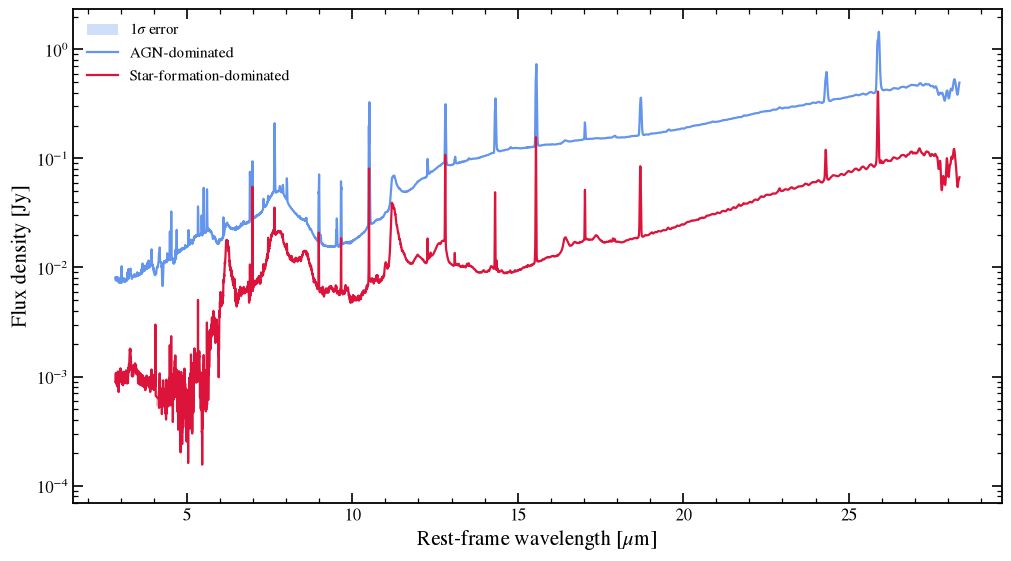

In [48]:
w_agn, f_agn, e_agn, _ = btb.stitch_spectra(spectra, "agn", with_errors=True)
w_sf,  f_sf,  e_sf,  _ = btb.stitch_spectra(spectra, "sf",  with_errors=True)
print(f"median S/N per channel: AGN {np.nanmedian(f_agn / e_agn):.0f}, SF {np.nanmedian(f_sf / e_sf):.0f}")

ERR_DISPLAY_SCALE = 1       # exaggerate the shaded errors for display only (e.g. 10 if they are invisible)
fig = bplt.plot_component_spectra(w_agn, f_agn, w_sf, f_sf, smooth=2, err_agn=e_agn, err_sf=e_sf,
                                  err_scale=ERR_DISPLAY_SCALE)
proj.savefig(fig, "component_spectra")
proj.save({"agn": (w_agn, f_agn, e_agn), "sf": (w_sf, f_sf, e_sf), "per_band": spectra}, "step5_spectra")
proj.export_spectra({"AGN": (w_agn, f_agn, e_agn), "SF": (w_sf, f_sf, e_sf)})   # wavelength, flux, error

**What to expect.** The AGN-dominated spectrum should show a steeply rising hot-dust continuum, silicate absorption at
9.7 $\mu$m and strong high-ionisation lines ([Ne V], [Ne VI], [O IV]); the star-formation-dominated spectrum should show
strong PAH features (6.2, 7.7, 8.6, 11.3, 12.7, 17 $\mu$m), relatively stronger low-ionisation lines and a fainter, flatter
continuum. The SF spaxels are those with $f_{\rm out} <$ `sf_max` in the stacked map - typically the parts of the ring
furthest from the bicone - so in bands with a small field of view (NIRSpec, MRS channel 1) there may be few or none.

In [50]:
proj.summary()

NGC5728: results/NGC5728
  component_spectra_AGN.txt                     1.1 MB
  component_spectra_SF.txt                      1.1 MB
  config.json                                   0.0 MB
  stacked_fraction_map.fits                     0.9 MB
  stacked_fraction_map.npz                      2.2 MB
  step1_line_maps.pkl                          39.2 MB
  step1_line_maps.settings.json                 0.0 MB
  step2a_disc_fits.pkl                          1.0 MB
  step2a_disc_fits.settings.json                0.0 MB
  step2b_outflow_fits.pkl                       3.2 MB
  step2b_outflow_fits.settings.json             0.0 MB
  step2c_combined_fits.pkl                     11.2 MB
  step2c_combined_fits.settings.json            0.0 MB
  step3_decompositions.pkl                     69.0 MB
  step3_decompositions.settings.json            0.0 MB
  step4_stacked_map.pkl                         8.9 MB
  step5_spectra.pkl                             2.0 MB
  figures/ (40 files)


## Notes and caveats

### Automated versus by-hand analysis
This notebook applies the same recipe to every line. A careful by-hand analysis can do better for individual
lines, and the results here will differ in detail from a tailored analysis (including the published one) if
the settings differ. The quantities that matter most:

* **masks** (`mask_percentile`, `dilate`, `percentile_over`) - set the field of view of each line and thus of the stack;
* **AGN position of each cube** - misalignments of a pixel shift the per-line maps relative to each other;
* **pixel scales** - set the physical size of each band in the stacked map;
* **double-Gaussian fitting** (`fitter`, `weighting`, initial guesses) - sets the dispersion medians;
* **model parameters and dispersions per line** in the decomposition (`DECOMP_PARAMS`, `DECOMP_SIGMAS`);
* **fit windows and continuum** of the spectra that are decomposed (`DECOMP_RECUT`).

### Doing it line by line
Every step is a plain function, so any line can be treated individually and the result swapped into the
dictionaries before stacking, e.g.:

```python
lm = btb.fit_line(cubes["ch3-short"], lines["NeII"].update(line_region=(12.79, 12.84), mask_percentile=65),
                  fitter="capfit", weighting="sqrt")              # re-measure one line
bplt.plot_spaxel_fits(lm)                                          # inspect it
fit = btb.fit_kinematics(lm, "combined", {**MODEL_PARAMS, "theta_out": (60, 110)}, method="emcee")
d = btb.decompose_line(lm, fit.params, sigma_disc=55, sigma_out=134,
                       cube=cubes["ch3-short"], recut=dict(window=(12.72, 12.92), line_region=(12.785, 12.835)))
bplt.plot_decomposition_spaxels(d, lm)                             # check the constrained fits
decomps["NeII"] = d                                                # replace, then re-run Step 4
```

Useful checks when tuning a line: the spaxel fits (`plot_spaxel_fits`, `plot_decomposition_spaxels`), the residual
maps (`plot_residual_maps`), the kinematic residuals (`plot_kinematic_fit`), and how the stacked map changes when
the line is left out (`compare_stacks`).

### Running on another galaxy
Use **`02_template_new_galaxy.ipynb`**: the same workflow with no NGC 5728-specific settings. (If you copy this
notebook instead, change Section 0 (name, data folder, redshift); then the AGN positions (Section 1), the line
list and settings (Section 2, start from the defaults by emptying `LINE_SETTINGS`), `MODEL_PARAMS` and the line
groups (Section 4), and choose `DECOMP_PARAMS = "fit_mean"` or `"fit_per_line"` and `DECOMP_SIGMAS = "measured"`
(Section 5), and empty `AGN_OVERRIDES`, `FRACTION_SIGMA_OVERRIDES` and `DECOMP_RECUT`.) Saved analyses can be re-opened with `btb.Project.open("NAME")`; `btb.list_projects()` lists them.

## 8. Aperture spectra: nuclear spectrum vs. the AGN-dominated spectrum

A **nuclear spectrum** is extracted in a circular aperture of 0.3" radius centred on the AGN, in every band, and
compared with the AGN-dominated spectrum from the decomposition (Step 5). More apertures can be added to
`APERTURES`, each with its own radius and position, given as an (east, north) offset from the AGN in arcsec, so the
aperture covers the same sky region in every band. The extraction uses exact fractional pixel weights (like photutils'
`method="exact"`), the same error method, detector-gap and field-of-view handling as Step 5, and the bands are stitched
with **the same band scale factors** as the AGN-dominated spectrum, so the two can be compared and subtracted directly.
A band is skipped if less than 90% of the aperture lies inside its observed field.

The aperture spectra are **not corrected for the point-spread function**: a fixed 0.3" aperture loses a growing fraction
of a point source's flux towards longer wavelengths (MIRI/MRS FWHM ~0.3" at 5 um, ~1" at 28 um). The band-to-band
rescaling hides the jumps between bands but not the slope this introduces within each band.

In [54]:
APERTURES = {   # name: radius [arcsec] and (east, north) offset of the centre from the AGN [arcsec]
    "nuclear": dict(radius_arcsec=0.3, offset_arcsec=(0.0, 0.0)),
    # "my region": dict(radius_arcsec=0.5, offset_arcsec=(1.0, -0.5)),
}
APERTURE_METHOD     = "exact"           # "exact" (fractional pixel weights) or "center" (whole pixels)
APERTURE_ERR_METHOD = ERR_METHOD                     # same as Step 5 (or "empirical", "max", None)

ap_spectra = btb.extract_apertures(cubes, APERTURES, method=APERTURE_METHOD, err_method=APERTURE_ERR_METHOD)
# stitch with exactly the band scale factors of the AGN-dominated spectrum (Step 5), so the two are comparable
_, _, _, AGN_SCALES = btb.stitch_spectra(spectra, "agn", with_errors=True, verbose=False)
ap_stitched = {}
for name in APERTURES:
    print(f"--- {name}")
    w, f, e, _ = btb.stitch_spectra(ap_spectra[name], "flux", with_errors=True, scales=AGN_SCALES)
    ap_stitched[name] = (w, f, e)
proj.save({"apertures": APERTURES, "per_band": ap_spectra, "stitched": ap_stitched}, "step6_aperture_spectra")
proj.export_spectra(ap_stitched, key="aperture_spectrum")          # wavelength, flux, error

ApertureSpectrum('nuclear', g395h-f290lp, r=0.3", centre (49.08, 43.74), 28.3 pix, covered 100%)
ApertureSpectrum('nuclear', ch1-short, r=0.3", centre (40.92, 38.13), 16.8 pix, covered 100%)
ApertureSpectrum('nuclear', ch1-medium, r=0.3", centre (41.76, 38.18), 16.7 pix, covered 100%)
ApertureSpectrum('nuclear', ch1-long, r=0.3", centre (39.88, 37.11), 16.7 pix, covered 100%)
ApertureSpectrum('nuclear', ch2-short, r=0.3", centre (36.99, 34.14), 9.8 pix, covered 100%)
ApertureSpectrum('nuclear', ch2-medium, r=0.3", centre (36.12, 35.21), 9.8 pix, covered 100%)
ApertureSpectrum('nuclear', ch2-long, r=0.3", centre (37.15, 34.16), 9.8 pix, covered 100%)
ApertureSpectrum('nuclear', ch3-short, r=0.3", centre (33.99, 36.10), 7.1 pix, covered 100%)
ApertureSpectrum('nuclear', ch3-medium, r=0.3", centre (34.97, 36.92), 7.1 pix, covered 100%)
ApertureSpectrum('nuclear', ch3-long, r=0.3", centre (34.96, 36.02), 7.1 pix, covered 100%)
ApertureSpectrum('nuclear', ch4-short, r=0.3", centre (24.92, 2

The apertures on the AGN outflow fraction map:

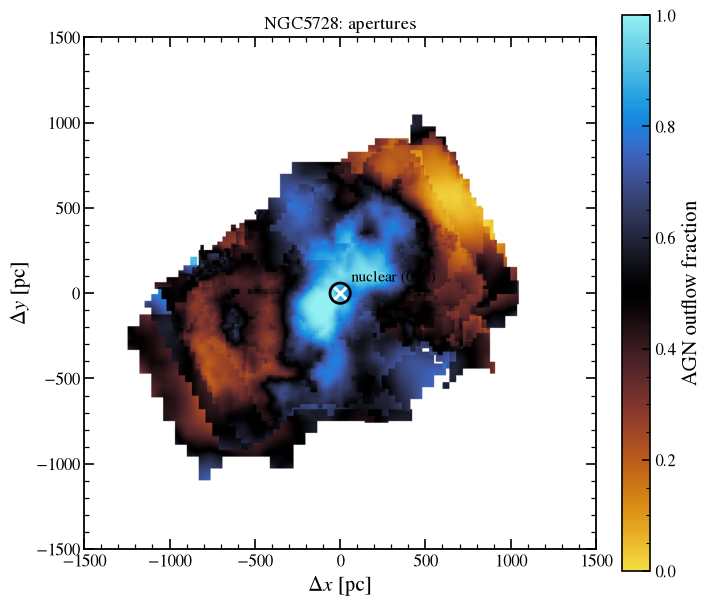

In [56]:
PC_PER_ARCSEC = next(iter(cubes.values())).pc_per_arcsec
fig = bplt.plot_apertures_on_map(stack, APERTURES, PC_PER_ARCSEC, which="f_out", lim_pc=1500,
                                 title=f"{GALAXY}: apertures")
proj.savefig(fig, "apertures_on_outflow_map")

The aperture spectra next to the AGN-dominated spectrum (errors shaded):

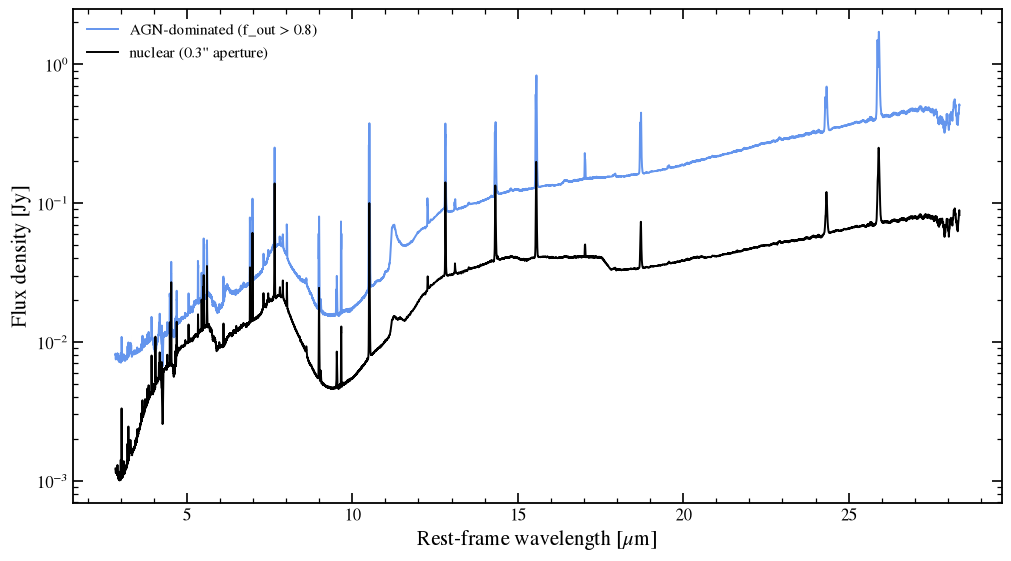

In [58]:
to_plot = {f"AGN-dominated (f_out > {AGN_MIN:g})": (w_agn, f_agn, e_agn)}
to_plot.update({f'{n} ({APERTURES[n]["radius_arcsec"]:g}" aperture)': ap_stitched[n] for n in APERTURES})
fig = bplt.plot_spectra(to_plot)
proj.savefig(fig, "aperture_vs_agn_dominated_spectrum")

### AGN-dominated spectrum minus the nuclear spectrum

The AGN-dominated region contains both the AGN point source and the outflow. Removing the nuclear aperture spectrum (taken to
represent the AGN point source) from it leaves the emission of the rest of the AGN-dominated region - mainly the outflow.
This is done **per band on the pixels themselves** (the aperture's pixel weights are removed from the region's), then
stitched with the AGN-dominated scale factors. The result equals *AGN-dominated - nuclear*, with errors that do not
double-count the pixels the two share; only the part of the aperture inside the region is removed (printed per band).

No matching scale is applied. `NUCLEAR_SCALE` (default 1) multiplies the nuclear contribution before removing it. A 0.3\"
aperture misses part of a point source's flux - increasingly towards long wavelengths (PSF FWHM ~0.3\" at 5 um, ~1\" at
28 um) - so some AGN light remains in the result. A PSF aperture correction (> 1) would remove it; a single number is only
an approximation, as the correction depends on wavelength.

  g395h-f290lp: 100.0% of the aperture lies in the agn region
     ch1-short: 100.0% of the aperture lies in the agn region
    ch1-medium: 100.0% of the aperture lies in the agn region
      ch1-long: 100.0% of the aperture lies in the agn region
     ch2-short:  97.7% of the aperture lies in the agn region  (only that part is removed)
    ch2-medium:  96.3% of the aperture lies in the agn region  (only that part is removed)
      ch2-long:  96.1% of the aperture lies in the agn region  (only that part is removed)
     ch3-short: 100.0% of the aperture lies in the agn region
    ch3-medium: 100.0% of the aperture lies in the agn region
      ch3-long: 100.0% of the aperture lies in the agn region
     ch4-short: 100.0% of the aperture lies in the agn region
    ch4-medium: 100.0% of the aperture lies in the agn region
      ch4-long: 100.0% of the aperture lies in the agn region
ch2-medium: scale = 1.017
ch2-long: scale = 0.974
ch3-short: scale = 0.939
ch3-medium: scale = 0.920
ch3-lo

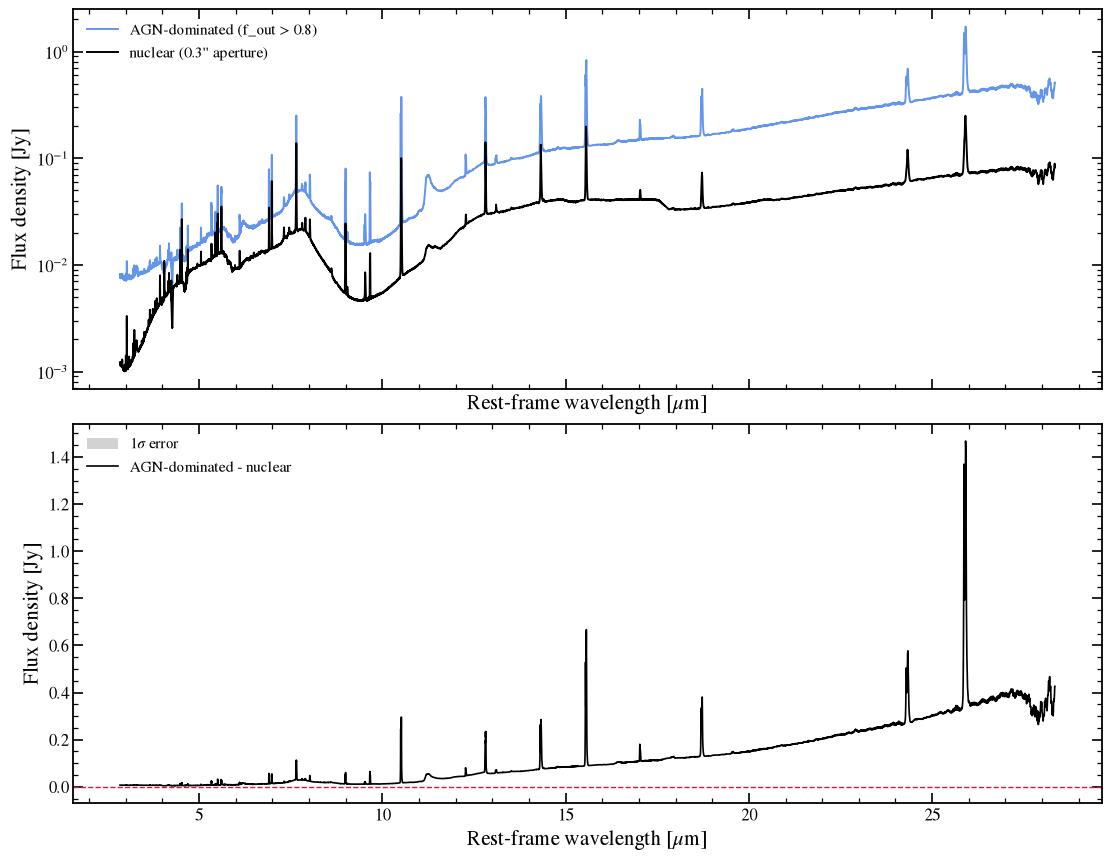

In [60]:
SUB_APERTURE  = "nuclear"
NUCLEAR_SCALE = 1.0      # factor applied to the aperture before removing it (1 = as extracted; > 1 e.g. a PSF correction)

res_bands = btb.subtract_aperture(cubes, spectra, ap_spectra[SUB_APERTURE], "agn", scale=NUCLEAR_SCALE)
w_res, f_res, e_res, _ = btb.stitch_spectra(res_bands, "flux", with_errors=True, scales=AGN_SCALES)
print(f"residual < 0 in {100 * np.nanmean(f_res < 0):.0f}% of channels")

w_n, f_n, e_n = ap_stitched[SUB_APERTURE]
lab_ap = f'{SUB_APERTURE} ({APERTURES[SUB_APERTURE]["radius_arcsec"]:g}" aperture)' + (f" x {NUCLEAR_SCALE:g}" if NUCLEAR_SCALE != 1 else "")
fig, axes = plt.subplots(2, 1, figsize=(11, 8.5), sharex=True, constrained_layout=True)
bplt.plot_spectra({f"AGN-dominated (f_out > {AGN_MIN:g})": (w_agn, f_agn, e_agn),
                   lab_ap: (w_n, NUCLEAR_SCALE * f_n, NUCLEAR_SCALE * e_n)}, colors={lab_ap: "k"}, ax=axes[0])
bplt.plot_residual_spectrum(w_res, f_res, e_res, label=f"AGN-dominated - {SUB_APERTURE}", ax=axes[1])
proj.savefig(fig, "agn_dominated_minus_aperture")
proj.export_spectra({f"AGN_minus_{SUB_APERTURE}": (w_res, f_res, e_res)}, key="aperture_spectrum")